# [14.3] V-JEPA from Scratch: A Persistence-Shortcut Lab

This notebook asks one deliberately adversarial question: **does a paper-mechanics V-JEPA trained on a tiny moving-object world learn enough dynamics to beat persistence on an unseen future mask?**

You will implement the released method's core mechanics, then try to falsify the stronger world-model claim.
The checked result is a negative result: this toy protocol can verify masked latent learning, but it does not
establish dynamics beyond copy-last-frame.

The evidence chain is visible and learner-owned:

> canonical clips -> collision-free splits -> tubelets -> spatial tube masks -> stop-gradient target -> L1 predictor -> EMA teacher -> future-mask stress test

The future-only mask is explicitly out of distribution relative to pretraining. Exact dynamics is an oracle,
persistence is the serious shortcut baseline, and all predictors are scored in the same EMA-teacher space. A
blank-future control tests whether the teacher's final-slice features retain context even when every future
pixel is erased.


## Learning Objectives

You will be able to:

- construct unique clip keys and physically canonical reversed keys;
- exclude forward and reversed collisions from pretraining, probe-fit, and held-out splits;
- implement Conv3D tubelets and spatial blocks repeated through time;
- verify that masked pixels cannot enter the online encoder;
- implement stop-gradient, target layer normalization, plain L1 prediction, and EMA;
- write and test the full `train_small_vjepa` loop yourself;
- separate an in-distribution spatial-tube task from an out-of-distribution future-mask stress test;
- fit balanced probe suites and score temporal reversal under physical labels;
- report tie-aware retrieval and tie counts against persistence, exact dynamics, and random controls;
- prove why the redundant 96-column temporal summary has effective-rank maximum 72.


In [1]:
import copy
import hashlib
import inspect
import json
import math
import os
import random
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import torch as t
import torch.nn.functional as F
from IPython.display import Markdown, display
from torch import Tensor, nn

chapter = "chapter14_jepa_world_models"
section = "part3_vjepa_from_scratch"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
section_dir = root_dir / chapter / "exercises" / section
assets_dir = root_dir / chapter / "instructions" / "assets"
if str(section_dir) not in sys.path:
    sys.path.insert(0, str(section_dir))

import tests
import solutions as reference
from solutions import (
    CollapseDiagnostics,
    DuplicateAudit,
    MetricInterval,
    PredictorMetrics,
    RetrievalDetails,
    ReversalCollisionAudit,
    VideoWorldBatch,
    VJEPAMetrics,
)

t.set_num_threads(min(8, os.cpu_count() or 1))
device = t.device(os.environ.get("VJEPA_DEVICE", "cpu"))
print(f"device={device}; torch={t.__version__}")

GT_TIER = "GT-1"
EXERCISE_ID = "14_3_vjepa_from_scratch"
DIFFICULTY = 4
IMPORTANCE = 5
EXPECTED_RUNTIME = "three 1,000-step reference seeds; typically under five minutes on CPU"
REQUIRES_GPU = False
EVALUATION_PROTOCOL_VERSION = "vjepa-14.3-paper-l1-tube-mask-v4"

DIRECTIONS = t.tensor([[1, 0], [-1, 0], [0, 1], [0, -1]], dtype=t.long)
REVERSED_DIRECTIONS = t.tensor([1, 0, 3, 2], dtype=t.long)


device=cpu; torch=2.12.1+cu132


## Part 1: Implement Paper Mechanics


### Exercise 1: Build Canonical, Collision-Free Video Worlds

A clip key is `(color, direction, start_x, start_y)`. Its physical reverse starts at the original final
position and moves in the opposite direction. Implement both key systems, then construct the held-out world so
forward and reversed test keys avoid pretraining keys and avoid each other.

<details><summary>Expected output</summary>

```text
train duplicates=0; test duplicates=0; train/test overlap=0
reversed/test and reversed/pretraining overlap=0
```
</details>

<details><summary>Help</summary>

For key `(c, d, x, y)`, the reversed start is `(x, y) + (frames - 1) * velocity[d]` modulo image size. Reversal is an involution: applying it twice must recover the original key.
</details>



<details>
<summary>Solution</summary>

```python
def reverse_canonical_keys(
    clip_keys: Tensor,
    *,
    frames: int,
    image_size: int,
    speed: int = 1,
) -> Tensor:
    """Return physical keys for clips played backward.

    A reversed clip starts at the original final position and moves in the
    opposite direction. This is a canonical physical key, not a relabeled copy
    of the original key.
    """

    if clip_keys.ndim != 2 or clip_keys.shape[1] != 4:
        raise ValueError("clip_keys must have shape (examples, 4).")
    if frames < 2 or image_size < 1 or speed < 1:
        raise ValueError("frames, image_size, and speed must define a valid moving clip.")
    keys = clip_keys.long()
    direction = keys[:, 1]
    if not ((0 <= direction) & (direction < 4)).all():
        raise ValueError("direction keys must lie in [0, 3].")
    velocity = DIRECTIONS.to(keys.device)[direction] * speed
    reversed_start = (keys[:, 2:] + (frames - 1) * velocity) % image_size
    reversed_direction = REVERSED_DIRECTIONS.to(keys.device)[direction]
    return t.stack([keys[:, 0], reversed_direction, reversed_start[:, 0], reversed_start[:, 1]], dim=1)

def make_moving_object_batch(
    n_samples: int,
    *,
    frames: int = 6,
    image_size: int = 16,
    object_size: int = 4,
    speed: int = 1,
    seed: int = 0,
    excluded_clip_keys: Tensor | None = None,
    excluded_reverse_against_keys: Tensor | None = None,
    disallow_reverse_pairs: bool = False,
    device: t.device | str = "cpu",
) -> VideoWorldBatch:
    """Generate balanced videos with unique ``(color, direction, x, y)`` keys."""

    if n_samples < 8:
        raise ValueError("n_samples must be at least 8 so every state is represented.")
    if frames < 4 or image_size < object_size + 2:
        raise ValueError("The requested world is too small for the motion horizon.")

    generator = t.Generator(device="cpu").manual_seed(seed)
    videos = t.zeros(n_samples, frames, 3, image_size, image_size)
    color_labels = t.arange(n_samples) % 2
    direction_labels = (t.arange(n_samples) // 2) % 4
    start_xy = t.empty(n_samples, 2, dtype=t.long)
    velocity_xy = DIRECTIONS[direction_labels] * speed

    excluded: set[tuple[int, int, int, int]] = set()
    if excluded_clip_keys is not None:
        if excluded_clip_keys.ndim != 2 or excluded_clip_keys.shape[1] != 4:
            raise ValueError("excluded_clip_keys must have shape (examples, 4).")
        excluded = {tuple(int(value) for value in row) for row in excluded_clip_keys.cpu().tolist()}

    reverse_excluded: set[tuple[int, int, int, int]] = set()
    if excluded_reverse_against_keys is not None:
        if excluded_reverse_against_keys.ndim != 2 or excluded_reverse_against_keys.shape[1] != 4:
            raise ValueError("excluded_reverse_against_keys must have shape (examples, 4).")
        reverse_excluded = {
            tuple(int(value) for value in row) for row in excluded_reverse_against_keys.cpu().tolist()
        }

    selected: set[tuple[int, int, int, int]] = set()

    for color in range(2):
        for direction in range(4):
            sample_indices = ((color_labels == color) & (direction_labels == direction)).nonzero().flatten()
            available = []
            dx, dy = (int(value) for value in DIRECTIONS[direction].tolist())
            reversed_direction = int(REVERSED_DIRECTIONS[direction])
            for position in range(image_size * image_size):
                x, y = position % image_size, position // image_size
                key = (color, direction, x, y)
                reversed_key = (
                    color,
                    reversed_direction,
                    (x + (frames - 1) * speed * dx) % image_size,
                    (y + (frames - 1) * speed * dy) % image_size,
                )
                if key in excluded or reversed_key in reverse_excluded:
                    continue
                if disallow_reverse_pairs and (key in selected or reversed_key in selected):
                    continue
                available.append(position)
            if len(sample_indices) > len(available):
                raise ValueError("Not enough unique clip keys remain after exclusions.")
            order = t.randperm(len(available), generator=generator)[: len(sample_indices)]
            chosen = t.tensor(available, dtype=t.long)[order]
            start_xy[sample_indices, 0] = chosen % image_size
            start_xy[sample_indices, 1] = chosen // image_size
            for position in chosen.tolist():
                selected.add((color, direction, position % image_size, position // image_size))

    for index in range(n_samples):
        dx, dy = velocity_xy[index].tolist()
        x0, y0 = (int(value) for value in start_xy[index].tolist())

        color = t.tensor([1.0, 0.12, 0.12]) if color_labels[index] == 0 else t.tensor([0.1, 0.7, 1.0])
        for frame in range(frames):
            x = (x0 + frame * dx) % image_size
            y = (y0 + frame * dy) % image_size
            for offset_y in range(object_size):
                for offset_x in range(object_size):
                    videos[index, frame, :, (y + offset_y) % image_size, (x + offset_x) % image_size] = color

    state_labels = color_labels * 4 + direction_labels
    clip_keys = t.stack([color_labels, direction_labels, start_xy[:, 0], start_xy[:, 1]], dim=1)
    return VideoWorldBatch(
        videos=videos.to(device),
        state_labels=state_labels.to(device),
        color_labels=color_labels.to(device),
        direction_labels=direction_labels.to(device),
        start_xy=start_xy.to(device),
        velocity_xy=velocity_xy.to(device),
        clip_keys=clip_keys.to(device),
    )

def make_disjoint_worlds(
    train_samples: int,
    test_samples: int,
    *,
    seed: int = 0,
    test_seed: int | None = None,
    device: t.device | str = "cpu",
) -> tuple[VideoWorldBatch, VideoWorldBatch]:
    """Build balanced train/test worlds whose clip keys cannot overlap."""

    train_world = make_moving_object_batch(train_samples, seed=seed, device=device)
    test_world = make_moving_object_batch(
        test_samples,
        seed=seed + 10_000 if test_seed is None else test_seed,
        excluded_clip_keys=train_world.clip_keys,
        excluded_reverse_against_keys=train_world.clip_keys,
        disallow_reverse_pairs=True,
        device=device,
    )
    audit = audit_clip_splits(train_world, test_world)
    if not audit.is_disjoint:
        raise RuntimeError(f"Clip split construction failed: {audit}")
    return train_world, test_world

def audit_clip_splits(train_world: VideoWorldBatch, test_world: VideoWorldBatch) -> DuplicateAudit:
    """Count within-split duplicates and cross-split overlap from explicit keys."""

    train_keys = {tuple(int(value) for value in row) for row in train_world.clip_keys.cpu().tolist()}
    test_keys = {tuple(int(value) for value in row) for row in test_world.clip_keys.cpu().tolist()}
    train_duplicates = len(train_world.clip_keys) - len(train_keys)
    test_duplicates = len(test_world.clip_keys) - len(test_keys)
    overlap = len(train_keys & test_keys)
    return DuplicateAudit(
        train_examples=len(train_world.clip_keys),
        test_examples=len(test_world.clip_keys),
        train_unique=len(train_keys),
        test_unique=len(test_keys),
        train_duplicates=train_duplicates,
        test_duplicates=test_duplicates,
        train_test_overlap=overlap,
        is_disjoint=train_duplicates == 0 and test_duplicates == 0 and overlap == 0,
    )
```

</details>


In [2]:
def reverse_canonical_keys(
    clip_keys: Tensor,
    *,
    frames: int,
    image_size: int,
    speed: int = 1,
) -> Tensor:
    """Return physical keys for clips played backward.

    A reversed clip starts at the original final position and moves in the
    opposite direction. This is a canonical physical key, not a relabeled copy
    of the original key.
    """

    if clip_keys.ndim != 2 or clip_keys.shape[1] != 4:
        raise ValueError("clip_keys must have shape (examples, 4).")
    if frames < 2 or image_size < 1 or speed < 1:
        raise ValueError("frames, image_size, and speed must define a valid moving clip.")
    keys = clip_keys.long()
    direction = keys[:, 1]
    if not ((0 <= direction) & (direction < 4)).all():
        raise ValueError("direction keys must lie in [0, 3].")
    velocity = DIRECTIONS.to(keys.device)[direction] * speed
    reversed_start = (keys[:, 2:] + (frames - 1) * velocity) % image_size
    reversed_direction = REVERSED_DIRECTIONS.to(keys.device)[direction]
    return t.stack([keys[:, 0], reversed_direction, reversed_start[:, 0], reversed_start[:, 1]], dim=1)

def make_moving_object_batch(
    n_samples: int,
    *,
    frames: int = 6,
    image_size: int = 16,
    object_size: int = 4,
    speed: int = 1,
    seed: int = 0,
    excluded_clip_keys: Tensor | None = None,
    excluded_reverse_against_keys: Tensor | None = None,
    disallow_reverse_pairs: bool = False,
    device: t.device | str = "cpu",
) -> VideoWorldBatch:
    """Generate balanced videos with unique ``(color, direction, x, y)`` keys."""

    if n_samples < 8:
        raise ValueError("n_samples must be at least 8 so every state is represented.")
    if frames < 4 or image_size < object_size + 2:
        raise ValueError("The requested world is too small for the motion horizon.")

    generator = t.Generator(device="cpu").manual_seed(seed)
    videos = t.zeros(n_samples, frames, 3, image_size, image_size)
    color_labels = t.arange(n_samples) % 2
    direction_labels = (t.arange(n_samples) // 2) % 4
    start_xy = t.empty(n_samples, 2, dtype=t.long)
    velocity_xy = DIRECTIONS[direction_labels] * speed

    excluded: set[tuple[int, int, int, int]] = set()
    if excluded_clip_keys is not None:
        if excluded_clip_keys.ndim != 2 or excluded_clip_keys.shape[1] != 4:
            raise ValueError("excluded_clip_keys must have shape (examples, 4).")
        excluded = {tuple(int(value) for value in row) for row in excluded_clip_keys.cpu().tolist()}

    reverse_excluded: set[tuple[int, int, int, int]] = set()
    if excluded_reverse_against_keys is not None:
        if excluded_reverse_against_keys.ndim != 2 or excluded_reverse_against_keys.shape[1] != 4:
            raise ValueError("excluded_reverse_against_keys must have shape (examples, 4).")
        reverse_excluded = {
            tuple(int(value) for value in row) for row in excluded_reverse_against_keys.cpu().tolist()
        }

    selected: set[tuple[int, int, int, int]] = set()

    for color in range(2):
        for direction in range(4):
            sample_indices = ((color_labels == color) & (direction_labels == direction)).nonzero().flatten()
            available = []
            dx, dy = (int(value) for value in DIRECTIONS[direction].tolist())
            reversed_direction = int(REVERSED_DIRECTIONS[direction])
            for position in range(image_size * image_size):
                x, y = position % image_size, position // image_size
                key = (color, direction, x, y)
                reversed_key = (
                    color,
                    reversed_direction,
                    (x + (frames - 1) * speed * dx) % image_size,
                    (y + (frames - 1) * speed * dy) % image_size,
                )
                if key in excluded or reversed_key in reverse_excluded:
                    continue
                if disallow_reverse_pairs and (key in selected or reversed_key in selected):
                    continue
                available.append(position)
            if len(sample_indices) > len(available):
                raise ValueError("Not enough unique clip keys remain after exclusions.")
            order = t.randperm(len(available), generator=generator)[: len(sample_indices)]
            chosen = t.tensor(available, dtype=t.long)[order]
            start_xy[sample_indices, 0] = chosen % image_size
            start_xy[sample_indices, 1] = chosen // image_size
            for position in chosen.tolist():
                selected.add((color, direction, position % image_size, position // image_size))

    for index in range(n_samples):
        dx, dy = velocity_xy[index].tolist()
        x0, y0 = (int(value) for value in start_xy[index].tolist())

        color = t.tensor([1.0, 0.12, 0.12]) if color_labels[index] == 0 else t.tensor([0.1, 0.7, 1.0])
        for frame in range(frames):
            x = (x0 + frame * dx) % image_size
            y = (y0 + frame * dy) % image_size
            for offset_y in range(object_size):
                for offset_x in range(object_size):
                    videos[index, frame, :, (y + offset_y) % image_size, (x + offset_x) % image_size] = color

    state_labels = color_labels * 4 + direction_labels
    clip_keys = t.stack([color_labels, direction_labels, start_xy[:, 0], start_xy[:, 1]], dim=1)
    return VideoWorldBatch(
        videos=videos.to(device),
        state_labels=state_labels.to(device),
        color_labels=color_labels.to(device),
        direction_labels=direction_labels.to(device),
        start_xy=start_xy.to(device),
        velocity_xy=velocity_xy.to(device),
        clip_keys=clip_keys.to(device),
    )

def make_disjoint_worlds(
    train_samples: int,
    test_samples: int,
    *,
    seed: int = 0,
    test_seed: int | None = None,
    device: t.device | str = "cpu",
) -> tuple[VideoWorldBatch, VideoWorldBatch]:
    """Build balanced train/test worlds whose clip keys cannot overlap."""

    train_world = make_moving_object_batch(train_samples, seed=seed, device=device)
    test_world = make_moving_object_batch(
        test_samples,
        seed=seed + 10_000 if test_seed is None else test_seed,
        excluded_clip_keys=train_world.clip_keys,
        excluded_reverse_against_keys=train_world.clip_keys,
        disallow_reverse_pairs=True,
        device=device,
    )
    audit = audit_clip_splits(train_world, test_world)
    if not audit.is_disjoint:
        raise RuntimeError(f"Clip split construction failed: {audit}")
    return train_world, test_world

def audit_clip_splits(train_world: VideoWorldBatch, test_world: VideoWorldBatch) -> DuplicateAudit:
    """Count within-split duplicates and cross-split overlap from explicit keys."""

    train_keys = {tuple(int(value) for value in row) for row in train_world.clip_keys.cpu().tolist()}
    test_keys = {tuple(int(value) for value in row) for row in test_world.clip_keys.cpu().tolist()}
    train_duplicates = len(train_world.clip_keys) - len(train_keys)
    test_duplicates = len(test_world.clip_keys) - len(test_keys)
    overlap = len(train_keys & test_keys)
    return DuplicateAudit(
        train_examples=len(train_world.clip_keys),
        test_examples=len(test_world.clip_keys),
        train_unique=len(train_keys),
        test_unique=len(test_keys),
        train_duplicates=train_duplicates,
        test_duplicates=test_duplicates,
        train_test_overlap=overlap,
        is_disjoint=train_duplicates == 0 and test_duplicates == 0 and overlap == 0,
    )

tests.test_make_moving_object_batch_exact(make_moving_object_batch)
tests.test_make_moving_object_batch_rejects_invalid_world(make_moving_object_batch)
tests.test_disjoint_world_splits_and_duplicate_audit(make_disjoint_worlds, audit_clip_splits)


All tests in `test_make_moving_object_batch_exact` passed!
All tests in `test_make_moving_object_batch_rejects_invalid_world` passed!


All tests in `test_disjoint_world_splits_and_duplicate_audit` passed!


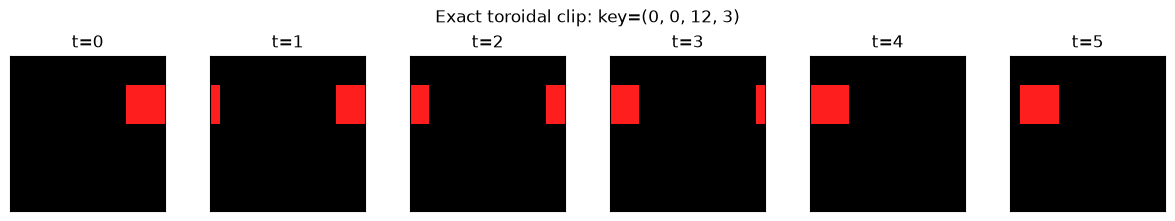

In [3]:
_, world_preview = make_disjoint_worlds(64, 64, seed=0)
fig, axes = plt.subplots(1, 6, figsize=(12, 2.1), constrained_layout=True)
for frame_index, axis in enumerate(axes):
    axis.imshow(world_preview.videos[24, frame_index].cpu().permute(1, 2, 0))
    axis.set_title(f"t={frame_index}")
    axis.set_xticks([])
    axis.set_yticks([])
fig.suptitle(f"Exact toroidal clip: key={tuple(world_preview.clip_keys[24].tolist())}")
plt.show()


![Expected exact video world](../../instructions/assets/vjepa_from_scratch_world.png)


### Exercise 2: Turn Video Into Tubelet Tokens

Implement the grid calculation and a strided `Conv3d`. For `(6, 16, 16)` video and `(2, 4, 4)` tubelets, the grid is `(3, 4, 4)`, or 48 tokens.

<details><summary>Help</summary>

PyTorch `Conv3d` expects `(batch, channels, time, height, width)`. Reject indivisible dimensions instead of silently truncating them.
</details>

<details><summary>Expected output</summary>

A batch of two clips becomes (2, 48, d_model) tokens on a (3, 4, 4) grid.

</details>

<details>
<summary>Solution</summary>

```python
def tubelet_grid(video_shape: tuple[int, int, int], tubelet_size: tuple[int, int, int]) -> tuple[int, int, int]:
    frames, height, width = video_shape
    tubelet_t, patch_h, patch_w = tubelet_size
    if frames % tubelet_t or height % patch_h or width % patch_w:
        raise ValueError("Video dimensions must be divisible by the tubelet dimensions.")
    return frames // tubelet_t, height // patch_h, width // patch_w

class TubeletEmbedding(nn.Module):
    def __init__(
        self,
        in_channels: int = 3,
        d_model: int = 24,
        tubelet_size: tuple[int, int, int] = (2, 4, 4),
    ) -> None:
        super().__init__()
        self.tubelet_size = tubelet_size
        self.proj = nn.Conv3d(
            in_channels,
            d_model,
            kernel_size=tubelet_size,
            stride=tubelet_size,
        )

    def forward(self, video: Tensor) -> tuple[Tensor, tuple[int, int, int]]:
        if video.ndim != 5:
            raise ValueError("video must have shape (batch, frames, channels, height, width).")
        tubelet_grid((video.shape[1], *video.shape[-2:]), self.tubelet_size)
        features = self.proj(video.permute(0, 2, 1, 3, 4))
        grid = tuple(int(value) for value in features.shape[-3:])
        tokens = features.flatten(2).transpose(1, 2)
        return tokens, grid
```

</details>


In [4]:
def tubelet_grid(video_shape: tuple[int, int, int], tubelet_size: tuple[int, int, int]) -> tuple[int, int, int]:
    frames, height, width = video_shape
    tubelet_t, patch_h, patch_w = tubelet_size
    if frames % tubelet_t or height % patch_h or width % patch_w:
        raise ValueError("Video dimensions must be divisible by the tubelet dimensions.")
    return frames // tubelet_t, height // patch_h, width // patch_w

class TubeletEmbedding(nn.Module):
    def __init__(
        self,
        in_channels: int = 3,
        d_model: int = 24,
        tubelet_size: tuple[int, int, int] = (2, 4, 4),
    ) -> None:
        super().__init__()
        self.tubelet_size = tubelet_size
        self.proj = nn.Conv3d(
            in_channels,
            d_model,
            kernel_size=tubelet_size,
            stride=tubelet_size,
        )

    def forward(self, video: Tensor) -> tuple[Tensor, tuple[int, int, int]]:
        if video.ndim != 5:
            raise ValueError("video must have shape (batch, frames, channels, height, width).")
        tubelet_grid((video.shape[1], *video.shape[-2:]), self.tubelet_size)
        features = self.proj(video.permute(0, 2, 1, 3, 4))
        grid = tuple(int(value) for value in features.shape[-3:])
        tokens = features.flatten(2).transpose(1, 2)
        return tokens, grid

tests.test_tubelet_grid_and_embedding(tubelet_grid, TubeletEmbedding)
tests.test_tubelet_embedding_rejects_wrong_rank(tubelet_grid, TubeletEmbedding)


All tests in `test_tubelet_grid_and_embedding` passed!
All tests in `test_tubelet_embedding_rejects_wrong_rank` passed!


### Exercise 3: Implement V-JEPA Spatial Tube Masks

Sample one contiguous spatial target block and repeat exactly the same block through all temporal tubelets. Also implement a separate full-future mask used only for the later stress test.

> **Paper connection.** Figure 2 of [Bardes et al.](https://arxiv.org/abs/2404.08471) uses spatial blocks
> repeated across the temporal dimension. The [released mask
> generator](https://github.com/facebookresearch/jepa/blob/main/src/masks/multiblock3d.py) defaults its
> temporal prediction scale to the full clip. Our tiny version uses one block rather than the release's
> multi-block sampling.

<details><summary>Expected output</summary>

```text
each 2x2 spatial block contributes 3 * 2 * 2 = 12 target tubelets
all temporal mask slices are identical
```
</details>

<details><summary>Help</summary>

Sample a spatial origin per clip, then broadcast the same block across time.

</details>

<details>
<summary>Solution</summary>

```python
def spatiotemporal_sincos(grid: tuple[int, int, int], d_model: int, *, device: t.device | str) -> Tensor:
    """Return fixed factorized time/y/x positional features with shape (1, tokens, d_model)."""

    if d_model < 6:
        raise ValueError("d_model must be at least 6.")
    coordinates = t.stack(
        t.meshgrid(
            t.arange(grid[0], device=device),
            t.arange(grid[1], device=device),
            t.arange(grid[2], device=device),
            indexing="ij",
        ),
        dim=-1,
    ).reshape(-1, 3)
    axis_dim = max(2, (d_model // 3) // 2 * 2)
    frequencies = t.exp(
        -math.log(10_000.0) * t.arange(0, axis_dim, 2, device=device) / axis_dim
    )
    parts = []
    for axis in range(3):
        angles = coordinates[:, axis : axis + 1].float() * frequencies[None]
        parts.append(t.cat([angles.sin(), angles.cos()], dim=-1))
    position = t.cat(parts, dim=-1)
    if position.shape[-1] < d_model:
        position = F.pad(position, (0, d_model - position.shape[-1]))
    return position[:, :d_model].unsqueeze(0)

def sample_spatial_tube_mask(
    batch_size: int,
    grid: tuple[int, int, int],
    *,
    block_shape: tuple[int, int] = (2, 2),
    generator: t.Generator | None = None,
    device: t.device | str = "cpu",
) -> Tensor:
    """Sample one spatial block per clip and repeat it through every time step."""

    time, height, width = grid
    bh, bw = block_shape
    if not (1 <= bh <= height and 1 <= bw <= width):
        raise ValueError("block_shape must fit inside the spatial tubelet grid.")

    mask = t.zeros(batch_size, time, height, width, dtype=t.bool)
    for batch_index in range(batch_size):
        start_y = int(t.randint(0, height - bh + 1, (), generator=generator))
        start_x = int(t.randint(0, width - bw + 1, (), generator=generator))
        mask[batch_index, :, start_y : start_y + bh, start_x : start_x + bw] = True
    return mask.flatten(1).to(device)

def future_prediction_mask(
    batch_size: int,
    grid: tuple[int, int, int],
    *,
    future_steps: int = 1,
    device: t.device | str = "cpu",
) -> Tensor:
    """Mask full final time slices for the out-of-distribution future diagnostic."""

    time, height, width = grid
    if not 1 <= future_steps < time:
        raise ValueError("future_steps must leave at least one visible temporal slice.")
    mask = t.zeros(batch_size, time, height, width, dtype=t.bool)
    mask[:, -future_steps:] = True
    return mask.flatten(1).to(device)

def expand_tubelet_mask(
    target_mask: Tensor,
    grid: tuple[int, int, int],
    tubelet_size: tuple[int, int, int],
) -> Tensor:
    """Expand a tubelet mask to a per-frame, per-pixel boolean mask."""

    if target_mask.ndim != 2 or target_mask.shape[1] != math.prod(grid):
        raise ValueError("target_mask must match the flattened tubelet grid.")
    expanded = target_mask.reshape(len(target_mask), *grid)
    for dimension, repeats in enumerate(tubelet_size, start=1):
        expanded = expanded.repeat_interleave(repeats, dim=dimension)
    return expanded
```

</details>


In [5]:
def spatiotemporal_sincos(grid: tuple[int, int, int], d_model: int, *, device: t.device | str) -> Tensor:
    """Return fixed factorized time/y/x positional features with shape (1, tokens, d_model)."""

    if d_model < 6:
        raise ValueError("d_model must be at least 6.")
    coordinates = t.stack(
        t.meshgrid(
            t.arange(grid[0], device=device),
            t.arange(grid[1], device=device),
            t.arange(grid[2], device=device),
            indexing="ij",
        ),
        dim=-1,
    ).reshape(-1, 3)
    axis_dim = max(2, (d_model // 3) // 2 * 2)
    frequencies = t.exp(
        -math.log(10_000.0) * t.arange(0, axis_dim, 2, device=device) / axis_dim
    )
    parts = []
    for axis in range(3):
        angles = coordinates[:, axis : axis + 1].float() * frequencies[None]
        parts.append(t.cat([angles.sin(), angles.cos()], dim=-1))
    position = t.cat(parts, dim=-1)
    if position.shape[-1] < d_model:
        position = F.pad(position, (0, d_model - position.shape[-1]))
    return position[:, :d_model].unsqueeze(0)

def sample_spatial_tube_mask(
    batch_size: int,
    grid: tuple[int, int, int],
    *,
    block_shape: tuple[int, int] = (2, 2),
    generator: t.Generator | None = None,
    device: t.device | str = "cpu",
) -> Tensor:
    """Sample one spatial block per clip and repeat it through every time step."""

    time, height, width = grid
    bh, bw = block_shape
    if not (1 <= bh <= height and 1 <= bw <= width):
        raise ValueError("block_shape must fit inside the spatial tubelet grid.")

    mask = t.zeros(batch_size, time, height, width, dtype=t.bool)
    for batch_index in range(batch_size):
        start_y = int(t.randint(0, height - bh + 1, (), generator=generator))
        start_x = int(t.randint(0, width - bw + 1, (), generator=generator))
        mask[batch_index, :, start_y : start_y + bh, start_x : start_x + bw] = True
    return mask.flatten(1).to(device)

def future_prediction_mask(
    batch_size: int,
    grid: tuple[int, int, int],
    *,
    future_steps: int = 1,
    device: t.device | str = "cpu",
) -> Tensor:
    """Mask full final time slices for the out-of-distribution future diagnostic."""

    time, height, width = grid
    if not 1 <= future_steps < time:
        raise ValueError("future_steps must leave at least one visible temporal slice.")
    mask = t.zeros(batch_size, time, height, width, dtype=t.bool)
    mask[:, -future_steps:] = True
    return mask.flatten(1).to(device)

def expand_tubelet_mask(
    target_mask: Tensor,
    grid: tuple[int, int, int],
    tubelet_size: tuple[int, int, int],
) -> Tensor:
    """Expand a tubelet mask to a per-frame, per-pixel boolean mask."""

    if target_mask.ndim != 2 or target_mask.shape[1] != math.prod(grid):
        raise ValueError("target_mask must match the flattened tubelet grid.")
    expanded = target_mask.reshape(len(target_mask), *grid)
    for dimension, repeats in enumerate(tubelet_size, start=1):
        expanded = expanded.repeat_interleave(repeats, dim=dimension)
    return expanded

tests.test_spatiotemporal_sincos_is_factorized(spatiotemporal_sincos)
tests.test_spatial_tube_masks_repeat_through_time(sample_spatial_tube_mask)
tests.test_future_prediction_mask_is_separate_diagnostic(future_prediction_mask)
tests.test_expand_tubelet_mask_matches_pixels(expand_tubelet_mask)


All tests in `test_spatiotemporal_sincos_is_factorized` passed!
All tests in `test_spatial_tube_masks_repeat_through_time` passed!
All tests in `test_future_prediction_mask_is_separate_diagnostic` passed!
All tests in `test_expand_tubelet_mask_matches_pixels` passed!


### Exercise 4: Encode Only Visible Context

Remove target tokens before the online transformer. Then prove masked-pixel invariance: replacing every masked pixel with random values must leave the visible representation exactly unchanged.

<details><summary>Interpretation</summary>

This semantic intervention catches target leakage that shape tests cannot. It works because the Conv3D tubelets do not overlap.
</details>

<details><summary>Expected output</summary>

Visible context has 36 tokens; replacing masked pixels changes none of them.

</details>

<details><summary>Help</summary>

Add position vectors before packing. Equal visible counts permit a batched reshape.

</details>

<details>
<summary>Solution</summary>

```python
def pack_visible_tokens(tokens: Tensor, target_mask: Tensor) -> Tensor:
    """Remove masked tokens while preserving batch and raster order."""

    if target_mask.shape != tokens.shape[:2]:
        raise ValueError("target_mask must match the batch and token dimensions.")
    visible_counts = (~target_mask).sum(dim=1)
    if not t.equal(visible_counts, visible_counts[:1].expand_as(visible_counts)):
        raise ValueError("Every sample must expose the same number of visible tokens.")
    return tokens[~target_mask].reshape(tokens.shape[0], int(visible_counts[0]), tokens.shape[-1])

class TokenEncoder(nn.Module):
    def __init__(self, d_model: int = 24, n_heads: int = 3, depth: int = 1, mlp_ratio: int = 2) -> None:
        super().__init__()
        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_model * mlp_ratio,
            dropout=0.0,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.blocks = nn.TransformerEncoder(layer, num_layers=depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)

    def forward(self, tokens: Tensor) -> Tensor:
        return self.norm(self.blocks(tokens))

class VideoEncoder(nn.Module):
    def __init__(
        self,
        d_model: int = 24,
        n_heads: int = 3,
        depth: int = 1,
        tubelet_size: tuple[int, int, int] = (2, 4, 4),
    ) -> None:
        super().__init__()
        self.d_model = d_model
        self.tubelet = TubeletEmbedding(d_model=d_model, tubelet_size=tubelet_size)
        self.encoder = TokenEncoder(d_model=d_model, n_heads=n_heads, depth=depth)

    def tokenize(self, video: Tensor) -> tuple[Tensor, Tensor, tuple[int, int, int]]:
        tokens, grid = self.tubelet(video)
        positions = spatiotemporal_sincos(grid, self.d_model, device=tokens.device)
        return tokens, positions, grid

    def encode_all(self, video: Tensor) -> tuple[Tensor, tuple[int, int, int]]:
        tokens, positions, grid = self.tokenize(video)
        return self.encoder(tokens + positions), grid

    def encode_visible(self, video: Tensor, target_mask: Tensor) -> tuple[Tensor, Tensor, tuple[int, int, int]]:
        tokens, positions, grid = self.tokenize(video)
        positioned = tokens + positions
        return self.encoder(pack_visible_tokens(positioned, target_mask)), positions, grid
```

</details>


In [6]:
def pack_visible_tokens(tokens: Tensor, target_mask: Tensor) -> Tensor:
    """Remove masked tokens while preserving batch and raster order."""

    if target_mask.shape != tokens.shape[:2]:
        raise ValueError("target_mask must match the batch and token dimensions.")
    visible_counts = (~target_mask).sum(dim=1)
    if not t.equal(visible_counts, visible_counts[:1].expand_as(visible_counts)):
        raise ValueError("Every sample must expose the same number of visible tokens.")
    return tokens[~target_mask].reshape(tokens.shape[0], int(visible_counts[0]), tokens.shape[-1])

class TokenEncoder(nn.Module):
    def __init__(self, d_model: int = 24, n_heads: int = 3, depth: int = 1, mlp_ratio: int = 2) -> None:
        super().__init__()
        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_model * mlp_ratio,
            dropout=0.0,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.blocks = nn.TransformerEncoder(layer, num_layers=depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)

    def forward(self, tokens: Tensor) -> Tensor:
        return self.norm(self.blocks(tokens))

class VideoEncoder(nn.Module):
    def __init__(
        self,
        d_model: int = 24,
        n_heads: int = 3,
        depth: int = 1,
        tubelet_size: tuple[int, int, int] = (2, 4, 4),
    ) -> None:
        super().__init__()
        self.d_model = d_model
        self.tubelet = TubeletEmbedding(d_model=d_model, tubelet_size=tubelet_size)
        self.encoder = TokenEncoder(d_model=d_model, n_heads=n_heads, depth=depth)

    def tokenize(self, video: Tensor) -> tuple[Tensor, Tensor, tuple[int, int, int]]:
        tokens, grid = self.tubelet(video)
        positions = spatiotemporal_sincos(grid, self.d_model, device=tokens.device)
        return tokens, positions, grid

    def encode_all(self, video: Tensor) -> tuple[Tensor, tuple[int, int, int]]:
        tokens, positions, grid = self.tokenize(video)
        return self.encoder(tokens + positions), grid

    def encode_visible(self, video: Tensor, target_mask: Tensor) -> tuple[Tensor, Tensor, tuple[int, int, int]]:
        tokens, positions, grid = self.tokenize(video)
        positioned = tokens + positions
        return self.encoder(pack_visible_tokens(positioned, target_mask)), positions, grid

tests.test_pack_visible_tokens_preserves_order(pack_visible_tokens)
tests.test_video_encoder_visible_shape(VideoEncoder)
tests.test_masked_pixels_cannot_change_visible_context(VideoEncoder)


All tests in `test_pack_visible_tokens_preserves_order` passed!
All tests in `test_video_encoder_visible_shape` passed!


All tests in `test_masked_pixels_cannot_change_visible_context` passed!


### Exercise 5: Assemble Online Encoder, Predictor, and Teacher

Reinsert learned mask tokens in the predictor, freeze a deep-copied target encoder, and layer-normalize the full target encoder output under `no_grad` before selecting target positions.

> **Paper connection.** The V-JEPA target sees the full unmasked clip; masking is applied after target encoding. The online encoder sees only context tokens. The target path is stop-gradient and follows the online path by EMA.

<details><summary>Expected output</summary>

Predictions and targets have shape (batch, 12, 24); only predictions require gradients.

</details>

<details><summary>Help</summary>

Scatter projected context into visible slots, use mask tokens elsewhere, then select targets.

</details>

<details>
<summary>Solution</summary>

```python
class VideoPredictor(nn.Module):
    def __init__(self, d_model: int = 24, n_heads: int = 3, depth: int = 1) -> None:
        super().__init__()
        self.context_projection = nn.Linear(d_model, d_model)
        self.mask_token = nn.Parameter(t.zeros(1, 1, d_model))
        self.encoder = TokenEncoder(d_model=d_model, n_heads=n_heads, depth=depth)
        self.output_projection = nn.Linear(d_model, d_model)
        nn.init.normal_(self.mask_token, std=0.02)

    def forward(self, visible: Tensor, target_mask: Tensor, positions: Tensor) -> Tensor:
        batch_size, n_tokens = target_mask.shape
        full = self.mask_token.expand(batch_size, n_tokens, -1).clone()
        projected_visible = self.context_projection(visible)
        full[~target_mask] = projected_visible.reshape(-1, projected_visible.shape[-1])
        predicted = self.output_projection(self.encoder(full + positions))
        n_targets = int(target_mask[0].sum())
        return predicted[target_mask].reshape(batch_size, n_targets, -1)

class SmallVJEPA(nn.Module):
    def __init__(
        self,
        d_model: int = 24,
        n_heads: int = 3,
        encoder_depth: int = 1,
        predictor_depth: int = 1,
        tubelet_size: tuple[int, int, int] = (2, 4, 4),
    ) -> None:
        super().__init__()
        self.context_encoder = VideoEncoder(d_model, n_heads, encoder_depth, tubelet_size)
        self.target_encoder = copy.deepcopy(self.context_encoder)
        for parameter in self.target_encoder.parameters():
            parameter.requires_grad_(False)
        self.predictor = VideoPredictor(d_model, n_heads, predictor_depth)

    def forward(self, video: Tensor, target_mask: Tensor) -> tuple[Tensor, Tensor, Tensor]:
        visible, positions, _ = self.context_encoder.encode_visible(video, target_mask)
        predicted = self.predictor(visible, target_mask, positions)
        with t.no_grad():
            target_all, _ = self.target_encoder.encode_all(video)
            target_all = F.layer_norm(target_all, (target_all.shape[-1],))
            n_targets = int(target_mask[0].sum())
            target = target_all[target_mask].reshape(video.shape[0], n_targets, -1)
        return predicted, target, visible
```

</details>


In [7]:
class VideoPredictor(nn.Module):
    def __init__(self, d_model: int = 24, n_heads: int = 3, depth: int = 1) -> None:
        super().__init__()
        self.context_projection = nn.Linear(d_model, d_model)
        self.mask_token = nn.Parameter(t.zeros(1, 1, d_model))
        self.encoder = TokenEncoder(d_model=d_model, n_heads=n_heads, depth=depth)
        self.output_projection = nn.Linear(d_model, d_model)
        nn.init.normal_(self.mask_token, std=0.02)

    def forward(self, visible: Tensor, target_mask: Tensor, positions: Tensor) -> Tensor:
        batch_size, n_tokens = target_mask.shape
        full = self.mask_token.expand(batch_size, n_tokens, -1).clone()
        projected_visible = self.context_projection(visible)
        full[~target_mask] = projected_visible.reshape(-1, projected_visible.shape[-1])
        predicted = self.output_projection(self.encoder(full + positions))
        n_targets = int(target_mask[0].sum())
        return predicted[target_mask].reshape(batch_size, n_targets, -1)

class SmallVJEPA(nn.Module):
    def __init__(
        self,
        d_model: int = 24,
        n_heads: int = 3,
        encoder_depth: int = 1,
        predictor_depth: int = 1,
        tubelet_size: tuple[int, int, int] = (2, 4, 4),
    ) -> None:
        super().__init__()
        self.context_encoder = VideoEncoder(d_model, n_heads, encoder_depth, tubelet_size)
        self.target_encoder = copy.deepcopy(self.context_encoder)
        for parameter in self.target_encoder.parameters():
            parameter.requires_grad_(False)
        self.predictor = VideoPredictor(d_model, n_heads, predictor_depth)

    def forward(self, video: Tensor, target_mask: Tensor) -> tuple[Tensor, Tensor, Tensor]:
        visible, positions, _ = self.context_encoder.encode_visible(video, target_mask)
        predicted = self.predictor(visible, target_mask, positions)
        with t.no_grad():
            target_all, _ = self.target_encoder.encode_all(video)
            target_all = F.layer_norm(target_all, (target_all.shape[-1],))
            n_targets = int(target_mask[0].sum())
            target = target_all[target_mask].reshape(video.shape[0], n_targets, -1)
        return predicted, target, visible

tests.test_predictor_places_visible_and_mask_tokens(VideoPredictor)
tests.test_small_vjepa_forward_stops_target_grad(SmallVJEPA)


All tests in `test_predictor_places_visible_and_mask_tokens` passed!
All tests in `test_small_vjepa_forward_stops_target_grad` passed!


### Exercise 6: Implement EMA and the Paper L1 Objective

Implement `target = momentum * target + (1 - momentum) * online` and mean absolute error from predictor outputs to detached, layer-normalized target features.

> **Paper connection.** The [paper architecture](https://arxiv.org/abs/2404.08471) labels this edge `L1` and
> stop-gradient; the [released training
> loop](https://github.com/facebookresearch/jepa/blob/main/app/vjepa/train.py) computes a power-1 absolute
> feature loss for the V-JEPA term. This lab uses that term alone. There is no variance or covariance penalty
> in the primary objective.

<details><summary>Common bugs</summary>

Normalizing the prediction as well as the target, using Smooth L1, letting gradients enter the teacher, or applying EMA before the online optimizer step.
</details>

<details><summary>Expected output</summary>

For target=0, online=2, momentum=0.75, EMA gives 0.5. L1 averages absolute errors.

</details>

<details><summary>Help</summary>

Detach target features, leave predictions unnormalized, and update matching parameter names.

</details>

<details>
<summary>Solution</summary>

```python
@t.no_grad()
def ema_update(target_encoder: nn.Module, context_encoder: nn.Module, momentum: float) -> None:
    if not 0.0 <= momentum <= 1.0:
        raise ValueError("EMA momentum must lie in [0, 1].")
    target_parameters = dict(target_encoder.named_parameters())
    context_parameters = dict(context_encoder.named_parameters())
    if target_parameters.keys() != context_parameters.keys():
        raise ValueError("Target and context encoders must have matching parameter names.")
    for name, target_parameter in target_parameters.items():
        target_parameter.mul_(momentum).add_(context_parameters[name], alpha=1.0 - momentum)
    target_buffers = dict(target_encoder.named_buffers())
    for name, target_buffer in target_buffers.items():
        target_buffer.copy_(dict(context_encoder.named_buffers())[name])

def vjepa_l1_loss(predicted: Tensor, target: Tensor) -> Tensor:
    """Paper objective: mean absolute error to stop-gradient teacher targets."""

    if predicted.shape != target.shape:
        raise ValueError("predicted and target latents must have the same shape.")
    return F.l1_loss(predicted, target.detach())
```

</details>


In [8]:
@t.no_grad()
def ema_update(target_encoder: nn.Module, context_encoder: nn.Module, momentum: float) -> None:
    if not 0.0 <= momentum <= 1.0:
        raise ValueError("EMA momentum must lie in [0, 1].")
    target_parameters = dict(target_encoder.named_parameters())
    context_parameters = dict(context_encoder.named_parameters())
    if target_parameters.keys() != context_parameters.keys():
        raise ValueError("Target and context encoders must have matching parameter names.")
    for name, target_parameter in target_parameters.items():
        target_parameter.mul_(momentum).add_(context_parameters[name], alpha=1.0 - momentum)
    target_buffers = dict(target_encoder.named_buffers())
    for name, target_buffer in target_buffers.items():
        target_buffer.copy_(dict(context_encoder.named_buffers())[name])

def vjepa_l1_loss(predicted: Tensor, target: Tensor) -> Tensor:
    """Paper objective: mean absolute error to stop-gradient teacher targets."""

    if predicted.shape != target.shape:
        raise ValueError("predicted and target latents must have the same shape.")
    return F.l1_loss(predicted, target.detach())

tests.test_ema_update_exact(ema_update)
tests.test_vjepa_l1_loss_is_exact_and_stops_target_grad(vjepa_l1_loss)


All tests in `test_ema_update_exact` passed!
All tests in `test_vjepa_l1_loss_is_exact_and_stops_target_grad` passed!


### Exercise 7: Write the Training Step and Loop

This is the P0 method exercise. Implement one optimizer/EMA step and `train_small_vjepa`; do not import either from `solutions.py`. The history has one key, `vjepa_l1`, because there is only one active loss.

<details><summary>Expected output</summary>

```text
history keys: {'vjepa_l1'}
short-run L1 decreases by at least 20 percent
the recorded training mask repeats through all three temporal slices
```
</details>

<details><summary>Help</summary>

Clear gradients, compute L1, backpropagate, clip and step online weights, then update EMA.

</details>

<details>
<summary>Solution</summary>

```python
def set_seed(seed: int) -> None:
    random.seed(seed)
    t.manual_seed(seed)
    if t.cuda.is_available():
        t.cuda.manual_seed_all(seed)

def vjepa_train_step(
    model: SmallVJEPA,
    video: Tensor,
    optimizer: t.optim.Optimizer,
    *,
    generator: t.Generator,
    ema_momentum: float,
    block_shape: tuple[int, int] = (2, 2),
) -> float:
    """Run one label-free L1/EMA update with a spatial mask repeated through time."""

    with t.no_grad():
        _, grid = model.context_encoder.tubelet(video[:1])
    mask = sample_spatial_tube_mask(
        len(video),
        grid,
        block_shape=block_shape,
        generator=generator,
        device=video.device,
    )
    predicted, target, _ = model(video, mask)
    loss = vjepa_l1_loss(predicted, target)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    ema_update(model.target_encoder, model.context_encoder, ema_momentum)
    return float(loss.detach())

def train_small_vjepa(
    train_world: VideoWorldBatch,
    *,
    steps: int = 240,
    batch_size: int = 32,
    learning_rate: float = 2e-3,
    ema_momentum: float = 0.97,
    block_shape: tuple[int, int] = (2, 2),
    seed: int = 0,
    model: SmallVJEPA | None = None,
) -> tuple[SmallVJEPA, dict[str, list[float]]]:
    """Train with only the V-JEPA L1 objective; no labels or auxiliary penalties."""

    set_seed(seed)
    device = train_world.videos.device
    model = (model or SmallVJEPA()).to(device)
    optimizer = t.optim.AdamW(
        [parameter for parameter in model.parameters() if parameter.requires_grad],
        lr=learning_rate,
        weight_decay=1e-4,
    )
    generator = t.Generator(device="cpu").manual_seed(seed + 1)
    history = {"vjepa_l1": []}

    model.train()
    for _ in range(steps):
        indices = t.randint(0, len(train_world.videos), (batch_size,), generator=generator).to(device)
        video = train_world.videos[indices]
        loss = vjepa_train_step(
            model,
            video,
            optimizer,
            generator=generator,
            ema_momentum=ema_momentum,
            block_shape=block_shape,
        )
        history["vjepa_l1"].append(loss)

    model.eval()
    return model, history
```

</details>


In [9]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    t.manual_seed(seed)
    if t.cuda.is_available():
        t.cuda.manual_seed_all(seed)

def vjepa_train_step(
    model: SmallVJEPA,
    video: Tensor,
    optimizer: t.optim.Optimizer,
    *,
    generator: t.Generator,
    ema_momentum: float,
    block_shape: tuple[int, int] = (2, 2),
) -> float:
    """Run one label-free L1/EMA update with a spatial mask repeated through time."""

    with t.no_grad():
        _, grid = model.context_encoder.tubelet(video[:1])
    mask = sample_spatial_tube_mask(
        len(video),
        grid,
        block_shape=block_shape,
        generator=generator,
        device=video.device,
    )
    predicted, target, _ = model(video, mask)
    loss = vjepa_l1_loss(predicted, target)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    ema_update(model.target_encoder, model.context_encoder, ema_momentum)
    return float(loss.detach())

def train_small_vjepa(
    train_world: VideoWorldBatch,
    *,
    steps: int = 240,
    batch_size: int = 32,
    learning_rate: float = 2e-3,
    ema_momentum: float = 0.97,
    block_shape: tuple[int, int] = (2, 2),
    seed: int = 0,
    model: SmallVJEPA | None = None,
) -> tuple[SmallVJEPA, dict[str, list[float]]]:
    """Train with only the V-JEPA L1 objective; no labels or auxiliary penalties."""

    set_seed(seed)
    device = train_world.videos.device
    model = (model or SmallVJEPA()).to(device)
    optimizer = t.optim.AdamW(
        [parameter for parameter in model.parameters() if parameter.requires_grad],
        lr=learning_rate,
        weight_decay=1e-4,
    )
    generator = t.Generator(device="cpu").manual_seed(seed + 1)
    history = {"vjepa_l1": []}

    model.train()
    for _ in range(steps):
        indices = t.randint(0, len(train_world.videos), (batch_size,), generator=generator).to(device)
        video = train_world.videos[indices]
        loss = vjepa_train_step(
            model,
            video,
            optimizer,
            generator=generator,
            ema_momentum=ema_momentum,
            block_shape=block_shape,
        )
        history["vjepa_l1"].append(loss)

    model.eval()
    return model, history

tests.test_training_updates_online_not_target_directly(train_small_vjepa, vjepa_train_step)
tests.test_training_contract_is_l1_only(train_small_vjepa, vjepa_train_step)
tests.test_short_training_improves_latent_objective(train_small_vjepa, SmallVJEPA)


All tests in `test_training_updates_online_not_target_directly` passed!
All tests in `test_training_contract_is_l1_only` passed!
All tests in `test_short_training_improves_latent_objective` passed!


### Exercise 8: Diagnose Collapse and Prove the Rank Bound

Average spatial tokens separately at each of three temporal slices, flatten those `3 * 24 = 72` coordinates, then append `final - initial` as a useful but redundant 24-column summary.

The resulting matrix has 96 columns but maximum rank 72: every appended coordinate is exactly one final-slice coordinate minus one initial-slice coordinate. Feature-wise centering and nonzero rescaling preserve that linear dependence.

<details><summary>Expected output</summary>

State features have 96 columns and rank at most 72; constant features have rank zero.

</details>

<details><summary>Help</summary>

Compute rank entropy from normalized squared singular values; handle the zero matrix explicitly.

</details>

<details>
<summary>Solution</summary>

```python
def collapse_diagnostics(features: Tensor, *, min_std: float = 0.05, min_rank: float = 2.0) -> CollapseDiagnostics:
    if features.ndim != 2 or features.shape[0] < 2:
        raise ValueError("features must have shape (examples, features) with at least two examples.")
    centered = features.float() - features.float().mean(dim=0, keepdim=True)
    feature_std = float(centered.std(dim=0, unbiased=False).mean())
    standardized = centered / centered.std(dim=0, unbiased=False, keepdim=True).clamp_min(1e-5)
    normalized = F.normalize(standardized, dim=-1)
    cosine = normalized @ normalized.T
    off_diagonal = cosine[~t.eye(cosine.shape[0], dtype=t.bool, device=cosine.device)]
    mean_pairwise_cosine = float(off_diagonal.abs().mean())
    singular_values = t.linalg.svdvals(standardized)
    probabilities = singular_values.square() / singular_values.square().sum().clamp_min(1e-12)
    effective_rank = float(t.exp(-(probabilities * probabilities.clamp_min(1e-12).log()).sum()))
    if not bool(singular_values.any()):
        effective_rank = 0.0  # The zero matrix has no represented direction.
    return CollapseDiagnostics(
        feature_std=feature_std,
        mean_pairwise_cosine=mean_pairwise_cosine,
        effective_rank=effective_rank,
        non_collapsed=feature_std >= min_std and effective_rank >= min_rank,
    )

def temporal_state_features(tokens: Tensor, grid: tuple[int, int, int]) -> Tensor:
    batch, _, d_model = tokens.shape
    time, height, width = grid
    by_time = tokens.reshape(batch, time, height * width, d_model).mean(dim=2)
    return t.cat([by_time.flatten(1), by_time[:, -1] - by_time[:, 0]], dim=-1)

def temporal_state_feature_rank_bound(grid: tuple[int, int, int], d_model: int) -> int:
    """Maximum rank before the redundant final-minus-initial summary is appended."""

    time, _, _ = grid
    if time < 1 or d_model < 1:
        raise ValueError("grid time and d_model must be positive.")
    return time * d_model
```

</details>


In [10]:
def collapse_diagnostics(features: Tensor, *, min_std: float = 0.05, min_rank: float = 2.0) -> CollapseDiagnostics:
    if features.ndim != 2 or features.shape[0] < 2:
        raise ValueError("features must have shape (examples, features) with at least two examples.")
    centered = features.float() - features.float().mean(dim=0, keepdim=True)
    feature_std = float(centered.std(dim=0, unbiased=False).mean())
    standardized = centered / centered.std(dim=0, unbiased=False, keepdim=True).clamp_min(1e-5)
    normalized = F.normalize(standardized, dim=-1)
    cosine = normalized @ normalized.T
    off_diagonal = cosine[~t.eye(cosine.shape[0], dtype=t.bool, device=cosine.device)]
    mean_pairwise_cosine = float(off_diagonal.abs().mean())
    singular_values = t.linalg.svdvals(standardized)
    probabilities = singular_values.square() / singular_values.square().sum().clamp_min(1e-12)
    effective_rank = float(t.exp(-(probabilities * probabilities.clamp_min(1e-12).log()).sum()))
    if not bool(singular_values.any()):
        effective_rank = 0.0  # The zero matrix has no represented direction.
    return CollapseDiagnostics(
        feature_std=feature_std,
        mean_pairwise_cosine=mean_pairwise_cosine,
        effective_rank=effective_rank,
        non_collapsed=feature_std >= min_std and effective_rank >= min_rank,
    )

def temporal_state_features(tokens: Tensor, grid: tuple[int, int, int]) -> Tensor:
    batch, _, d_model = tokens.shape
    time, height, width = grid
    by_time = tokens.reshape(batch, time, height * width, d_model).mean(dim=2)
    return t.cat([by_time.flatten(1), by_time[:, -1] - by_time[:, 0]], dim=-1)

def temporal_state_feature_rank_bound(grid: tuple[int, int, int], d_model: int) -> int:
    """Maximum rank before the redundant final-minus-initial summary is appended."""

    time, _, _ = grid
    if time < 1 or d_model < 1:
        raise ValueError("grid time and d_model must be positive.")
    return time * d_model

tests.test_collapse_diagnostics_exact(collapse_diagnostics)
tests.test_temporal_state_features_keep_order(temporal_state_features, temporal_state_feature_rank_bound)


All tests in `test_collapse_diagnostics_exact` passed!
All tests in `test_temporal_state_features_keep_order` passed!


### Exercise 9: Implement Ridge Probes

Keep color, direction, and combined state separate. A perfect color probe is not evidence of motion understanding.

<details><summary>Expected output</summary>

An exact one-hot fixture is classified perfectly; a permuted label mapping fails.

</details>

<details><summary>Help</summary>

Append a bias column and solve the regularized normal equations; do not penalize the bias.

</details>

<details>
<summary>Solution</summary>

```python
def fit_ridge_probe(features: Tensor, labels: Tensor, n_classes: int, ridge: float = 1e-2) -> Tensor:
    x = t.cat([features.float(), t.ones(features.shape[0], 1, device=features.device)], dim=1)
    y = F.one_hot(labels.long(), n_classes).float()
    identity = t.eye(x.shape[1], device=x.device)
    identity[-1, -1] = 0.0
    return t.linalg.solve(x.T @ x + ridge * identity, x.T @ y)

def probe_accuracy(features: Tensor, labels: Tensor, weights: Tensor) -> float:
    x = t.cat([features.float(), t.ones(features.shape[0], 1, device=features.device)], dim=1)
    return float((x @ weights).argmax(dim=-1).eq(labels).float().mean())
```

</details>


In [11]:
def fit_ridge_probe(features: Tensor, labels: Tensor, n_classes: int, ridge: float = 1e-2) -> Tensor:
    x = t.cat([features.float(), t.ones(features.shape[0], 1, device=features.device)], dim=1)
    y = F.one_hot(labels.long(), n_classes).float()
    identity = t.eye(x.shape[1], device=x.device)
    identity[-1, -1] = 0.0
    return t.linalg.solve(x.T @ x + ridge * identity, x.T @ y)

def probe_accuracy(features: Tensor, labels: Tensor, weights: Tensor) -> float:
    x = t.cat([features.float(), t.ones(features.shape[0], 1, device=features.device)], dim=1)
    return float((x @ weights).argmax(dim=-1).eq(labels).float().mean())

tests.test_ridge_probe_and_random_labels(fit_ridge_probe, probe_accuracy)


All tests in `test_ridge_probe_and_random_labels` passed!


### Exercise 10: Implement Key-Matched, Tie-Aware Retrieval

Each query key must occur exactly once in the gallery. Award fractional credit when the true target shares the top score, and retain every per-query tie count for reporting.

<details><summary>Expected output</summary>

Two equal top scores give 1/2 credit only when the true key is one of them.

</details>

<details><summary>Help</summary>

Match keys first. Reordering the gallery must not change accuracy.

</details>

<details>
<summary>Solution</summary>

```python
def retrieval_details(
    query: Tensor,
    gallery: Tensor,
    query_keys: Tensor,
    gallery_keys: Tensor,
    *,
    tie_atol: float = 1e-7,
) -> RetrievalDetails:
    """Evaluate key-matched retrieval with fractional credit for exact top-score ties."""

    if query.ndim != 2 or gallery.ndim != 2 or query.shape[1] != gallery.shape[1]:
        raise ValueError("query and gallery must be rank-two tensors with matching feature dimensions.")
    query_keys = query_keys.reshape(len(query), -1)
    gallery_keys = gallery_keys.reshape(len(gallery), -1)
    if query_keys.shape[1] != gallery_keys.shape[1]:
        raise ValueError("query_keys and gallery_keys must have matching key dimensions.")
    key_matches = (query_keys[:, None, :] == gallery_keys[None, :, :]).all(dim=-1)
    if not (key_matches.sum(dim=1) == 1).all():
        raise ValueError("Every query key must appear exactly once in the unique gallery.")

    similarities = F.normalize(query.float(), dim=-1) @ F.normalize(gallery.float(), dim=-1).T
    true_indices = key_matches.float().argmax(dim=1)
    row_indices = t.arange(len(query), device=query.device)
    true_scores = similarities[row_indices, true_indices]
    maximum_scores = similarities.max(dim=1).values
    tied_for_first = t.isclose(similarities, maximum_scores[:, None], rtol=0.0, atol=tie_atol)
    tie_counts = tied_for_first.sum(dim=1)
    true_tied = tied_for_first[row_indices, true_indices]
    tie_credit = true_tied.float() / tie_counts.float()
    true_ranks = 1 + (similarities > true_scores[:, None] + tie_atol).sum(dim=1)
    return RetrievalDetails(
        accuracy=float(tie_credit.mean()),
        top1_indices=similarities.argmax(dim=1),
        true_indices=true_indices,
        true_ranks=true_ranks,
        tie_counts=tie_counts,
        matched_cosines=true_scores,
    )

def retrieval_accuracy(query: Tensor, gallery: Tensor, query_keys: Tensor, gallery_keys: Tensor) -> float:
    return retrieval_details(query, gallery, query_keys, gallery_keys).accuracy
```

</details>


In [12]:
def retrieval_details(
    query: Tensor,
    gallery: Tensor,
    query_keys: Tensor,
    gallery_keys: Tensor,
    *,
    tie_atol: float = 1e-7,
) -> RetrievalDetails:
    """Evaluate key-matched retrieval with fractional credit for exact top-score ties."""

    if query.ndim != 2 or gallery.ndim != 2 or query.shape[1] != gallery.shape[1]:
        raise ValueError("query and gallery must be rank-two tensors with matching feature dimensions.")
    query_keys = query_keys.reshape(len(query), -1)
    gallery_keys = gallery_keys.reshape(len(gallery), -1)
    if query_keys.shape[1] != gallery_keys.shape[1]:
        raise ValueError("query_keys and gallery_keys must have matching key dimensions.")
    key_matches = (query_keys[:, None, :] == gallery_keys[None, :, :]).all(dim=-1)
    if not (key_matches.sum(dim=1) == 1).all():
        raise ValueError("Every query key must appear exactly once in the unique gallery.")

    similarities = F.normalize(query.float(), dim=-1) @ F.normalize(gallery.float(), dim=-1).T
    true_indices = key_matches.float().argmax(dim=1)
    row_indices = t.arange(len(query), device=query.device)
    true_scores = similarities[row_indices, true_indices]
    maximum_scores = similarities.max(dim=1).values
    tied_for_first = t.isclose(similarities, maximum_scores[:, None], rtol=0.0, atol=tie_atol)
    tie_counts = tied_for_first.sum(dim=1)
    true_tied = tied_for_first[row_indices, true_indices]
    tie_credit = true_tied.float() / tie_counts.float()
    true_ranks = 1 + (similarities > true_scores[:, None] + tie_atol).sum(dim=1)
    return RetrievalDetails(
        accuracy=float(tie_credit.mean()),
        top1_indices=similarities.argmax(dim=1),
        true_indices=true_indices,
        true_ranks=true_ranks,
        tie_counts=tie_counts,
        matched_cosines=true_scores,
    )

def retrieval_accuracy(query: Tensor, gallery: Tensor, query_keys: Tensor, gallery_keys: Tensor) -> float:
    return retrieval_details(query, gallery, query_keys, gallery_keys).accuracy

tests.test_retrieval_is_key_matched_and_tie_aware(retrieval_details, retrieval_accuracy)


All tests in `test_retrieval_is_key_matched_and_tie_aware` passed!


## Part 2: Falsify the Dynamics Claim


### Exercise 11: Encode Future Targets and Physical Baselines

The future-only mask is an out-of-distribution diagnostic, not the pretraining mask. Convert the learned predictor, blank-future, copy-last-frame, exact dynamics, and a random predictor into the same final-slice EMA-teacher latent space.

**Why blank the future?** The teacher attends to the entire clip before we select its final tokens. Those
tokens can identify a clip from the past. Keep frames 0–3, zero frames 4–5, and measure how much retrieval
survives. This control has no future image prediction at all.

The exact-dynamics oracle may read the generator's velocity labels; the learned predictor, blank-future, and persistence controls may only use visible pixels. An oracle score of one checks the evaluator, not a learned capability.

<details><summary>Expected output</summary>

Exact dynamics reproduces every future pixel; blank-future keeps only frames 0–3.

</details>

<details><summary>Help</summary>

The final two frames form one temporal tubelet. Normalize teacher features before selecting it.

</details>

<details>
<summary>Solution</summary>

```python
@t.no_grad()
def encode_state_features(encoder: VideoEncoder, videos: Tensor, batch_size: int = 64) -> Tensor:
    parts = []
    for start in range(0, len(videos), batch_size):
        tokens, grid = encoder.encode_all(videos[start : start + batch_size])
        parts.append(temporal_state_features(tokens, grid))
    return t.cat(parts)

@t.no_grad()
def future_teacher_latents(encoder: VideoEncoder, videos: Tensor, batch_size: int = 64) -> Tensor:
    """Extract the final temporal tubelet slice from the EMA teacher."""

    parts = []
    for start in range(0, len(videos), batch_size):
        tokens, grid = encoder.encode_all(videos[start : start + batch_size])
        tokens = F.layer_norm(tokens, (tokens.shape[-1],))
        time, height, width = grid
        final_slice = tokens.reshape(len(tokens), time, height * width, -1)[:, -1]
        parts.append(final_slice.flatten(1))
    return t.cat(parts)

@t.no_grad()
def predict_future_features(model: SmallVJEPA, videos: Tensor, batch_size: int = 64) -> tuple[Tensor, Tensor]:
    predicted_parts, target_parts = [], []
    for start in range(0, len(videos), batch_size):
        batch = videos[start : start + batch_size]
        _, grid = model.target_encoder.encode_all(batch[:1])
        mask = future_prediction_mask(len(batch), grid, device=batch.device)
        predicted, target, _ = model(batch, mask)
        predicted_parts.append(predicted.flatten(1))
        target_parts.append(target.flatten(1))
    return t.cat(predicted_parts), t.cat(target_parts)

@t.no_grad()
def blank_future_video(world: VideoWorldBatch, context_frames: int = 4) -> Tensor:
    """Keep context and erase all future pixels; never read the true future."""

    if not 1 <= context_frames < world.videos.shape[1]:
        raise ValueError("context_frames must leave a visible prefix and a future.")
    result = t.zeros_like(world.videos)
    result[:, :context_frames] = world.videos[:, :context_frames]
    return result

@t.no_grad()
def copy_last_frame_video(world: VideoWorldBatch, context_frames: int = 4) -> Tensor:
    """Fill every future frame with the last visible context frame."""

    if not 1 <= context_frames < world.videos.shape[1]:
        raise ValueError("context_frames must leave at least one future frame.")
    predicted_video = world.videos.clone()
    predicted_video[:, context_frames:] = world.videos[:, context_frames - 1 : context_frames]
    return predicted_video

@t.no_grad()
def exact_dynamics_video(world: VideoWorldBatch, context_frames: int = 4) -> Tensor:
    """Roll the last context frame forward by the known physical velocity."""

    if not 1 <= context_frames < world.videos.shape[1]:
        raise ValueError("context_frames must leave at least one future frame.")
    predicted_video = world.videos.clone()
    context_last = world.videos[:, context_frames - 1]
    for index, (frame, velocity) in enumerate(zip(context_last, world.velocity_xy)):
        dx, dy = (int(value) for value in velocity.tolist())
        for future_index in range(context_frames, world.videos.shape[1]):
            steps = future_index - context_frames + 1
            predicted_video[index, future_index] = t.roll(
                frame,
                shifts=(steps * dy, steps * dx),
                dims=(-2, -1),
            )
    return predicted_video

@t.no_grad()
def exact_dynamics_prediction(world: VideoWorldBatch) -> Tensor:
    """Return the final frame from the exact two-frame future rollout."""

    return exact_dynamics_video(world)[:, -1]

def reverse_direction_labels(direction_labels: Tensor) -> Tensor:
    """Map right/left and down/up labels to the direction seen after reversal."""

    if not ((0 <= direction_labels) & (direction_labels < 4)).all():
        raise ValueError("direction labels must lie in [0, 3].")
    return REVERSED_DIRECTIONS.to(direction_labels.device)[direction_labels.long()]
```

</details>


In [13]:
@t.no_grad()
def encode_state_features(encoder: VideoEncoder, videos: Tensor, batch_size: int = 64) -> Tensor:
    parts = []
    for start in range(0, len(videos), batch_size):
        tokens, grid = encoder.encode_all(videos[start : start + batch_size])
        parts.append(temporal_state_features(tokens, grid))
    return t.cat(parts)

@t.no_grad()
def future_teacher_latents(encoder: VideoEncoder, videos: Tensor, batch_size: int = 64) -> Tensor:
    """Extract the final temporal tubelet slice from the EMA teacher."""

    parts = []
    for start in range(0, len(videos), batch_size):
        tokens, grid = encoder.encode_all(videos[start : start + batch_size])
        tokens = F.layer_norm(tokens, (tokens.shape[-1],))
        time, height, width = grid
        final_slice = tokens.reshape(len(tokens), time, height * width, -1)[:, -1]
        parts.append(final_slice.flatten(1))
    return t.cat(parts)

@t.no_grad()
def predict_future_features(model: SmallVJEPA, videos: Tensor, batch_size: int = 64) -> tuple[Tensor, Tensor]:
    predicted_parts, target_parts = [], []
    for start in range(0, len(videos), batch_size):
        batch = videos[start : start + batch_size]
        _, grid = model.target_encoder.encode_all(batch[:1])
        mask = future_prediction_mask(len(batch), grid, device=batch.device)
        predicted, target, _ = model(batch, mask)
        predicted_parts.append(predicted.flatten(1))
        target_parts.append(target.flatten(1))
    return t.cat(predicted_parts), t.cat(target_parts)

@t.no_grad()
def blank_future_video(world: VideoWorldBatch, context_frames: int = 4) -> Tensor:
    """Keep context and erase all future pixels; never read the true future."""

    if not 1 <= context_frames < world.videos.shape[1]:
        raise ValueError("context_frames must leave a visible prefix and a future.")
    result = t.zeros_like(world.videos)
    result[:, :context_frames] = world.videos[:, :context_frames]
    return result

@t.no_grad()
def copy_last_frame_video(world: VideoWorldBatch, context_frames: int = 4) -> Tensor:
    """Fill every future frame with the last visible context frame."""

    if not 1 <= context_frames < world.videos.shape[1]:
        raise ValueError("context_frames must leave at least one future frame.")
    predicted_video = world.videos.clone()
    predicted_video[:, context_frames:] = world.videos[:, context_frames - 1 : context_frames]
    return predicted_video

@t.no_grad()
def exact_dynamics_video(world: VideoWorldBatch, context_frames: int = 4) -> Tensor:
    """Roll the last context frame forward by the known physical velocity."""

    if not 1 <= context_frames < world.videos.shape[1]:
        raise ValueError("context_frames must leave at least one future frame.")
    predicted_video = world.videos.clone()
    context_last = world.videos[:, context_frames - 1]
    for index, (frame, velocity) in enumerate(zip(context_last, world.velocity_xy)):
        dx, dy = (int(value) for value in velocity.tolist())
        for future_index in range(context_frames, world.videos.shape[1]):
            steps = future_index - context_frames + 1
            predicted_video[index, future_index] = t.roll(
                frame,
                shifts=(steps * dy, steps * dx),
                dims=(-2, -1),
            )
    return predicted_video

@t.no_grad()
def exact_dynamics_prediction(world: VideoWorldBatch) -> Tensor:
    """Return the final frame from the exact two-frame future rollout."""

    return exact_dynamics_video(world)[:, -1]

def reverse_direction_labels(direction_labels: Tensor) -> Tensor:
    """Map right/left and down/up labels to the direction seen after reversal."""

    if not ((0 <= direction_labels) & (direction_labels < 4)).all():
        raise ValueError("direction labels must lie in [0, 3].")
    return REVERSED_DIRECTIONS.to(direction_labels.device)[direction_labels.long()]

tests.test_encode_and_future_helpers_match_direct_model_calls(
    encode_state_features, future_teacher_latents, predict_future_features
)
tests.test_future_video_baselines_are_semantic(
    copy_last_frame_video, exact_dynamics_video, exact_dynamics_prediction
)
tests.test_reverse_direction_labels_are_physical(reverse_direction_labels)
tests.test_blank_future_removes_future_without_mutation(blank_future_video)
tests.test_future_teacher_features_can_retain_context(future_teacher_latents)


All tests in `test_encode_and_future_helpers_match_direct_model_calls` passed!
All tests in `test_future_video_baselines_are_semantic` passed!
All tests in `test_reverse_direction_labels_are_physical` passed!


All tests in `test_blank_future_removes_future_without_mutation` passed!
All tests in `test_future_teacher_features_can_retain_context` passed!


### Exercise 12: Audit Physical Reversal Before Scoring It

Derive reversed keys from actual start positions and velocities. Reject the run unless reversed held-out keys are unique and have zero overlap with pretraining, the explicit probe-fit subset, and forward held-out keys.

<details><summary>Expected output</summary>

Reversing keys twice recovers the original keys; all required intersections are empty.

</details>

<details><summary>Help</summary>

The reversed start is the forward final position, and the velocity changes sign.

</details>

<details>
<summary>Solution</summary>

```python
def physical_reverse_keys(world: VideoWorldBatch) -> Tensor:
    """Canonical keys of ``world.videos.flip(1)`` from observed physical state."""

    final_xy = (world.start_xy + (world.videos.shape[1] - 1) * world.velocity_xy) % world.videos.shape[-1]
    reversed_direction = REVERSED_DIRECTIONS.to(world.direction_labels.device)[world.direction_labels]
    return t.stack(
        [world.color_labels, reversed_direction, final_xy[:, 0], final_xy[:, 1]],
        dim=1,
    )

def audit_reversal_collisions(
    pretraining_world: VideoWorldBatch,
    probe_fit_keys: Tensor,
    test_world: VideoWorldBatch,
) -> ReversalCollisionAudit:
    """Audit reversed test clips against every split that could leak labels."""

    reversed_keys = physical_reverse_keys(test_world)

    def key_set(keys: Tensor) -> set[tuple[int, int, int, int]]:
        return {tuple(int(value) for value in row) for row in keys.cpu().tolist()}

    reverse_set = key_set(reversed_keys)
    pretraining_set = key_set(pretraining_world.clip_keys)
    probe_fit_set = key_set(probe_fit_keys)
    test_set = key_set(test_world.clip_keys)
    reversed_duplicates = len(reversed_keys) - len(reverse_set)
    pretraining_overlap = len(reverse_set & pretraining_set)
    probe_fit_overlap = len(reverse_set & probe_fit_set)
    test_overlap = len(reverse_set & test_set)
    return ReversalCollisionAudit(
        reversed_examples=len(reversed_keys),
        reversed_unique=len(reverse_set),
        reversed_duplicates=reversed_duplicates,
        reversed_pretraining_overlap=pretraining_overlap,
        reversed_probe_fit_overlap=probe_fit_overlap,
        reversed_test_overlap=test_overlap,
        collision_free=(
            reversed_duplicates == 0
            and pretraining_overlap == 0
            and probe_fit_overlap == 0
            and test_overlap == 0
        ),
    )
```

</details>


In [14]:
def physical_reverse_keys(world: VideoWorldBatch) -> Tensor:
    """Canonical keys of ``world.videos.flip(1)`` from observed physical state."""

    final_xy = (world.start_xy + (world.videos.shape[1] - 1) * world.velocity_xy) % world.videos.shape[-1]
    reversed_direction = REVERSED_DIRECTIONS.to(world.direction_labels.device)[world.direction_labels]
    return t.stack(
        [world.color_labels, reversed_direction, final_xy[:, 0], final_xy[:, 1]],
        dim=1,
    )

def audit_reversal_collisions(
    pretraining_world: VideoWorldBatch,
    probe_fit_keys: Tensor,
    test_world: VideoWorldBatch,
) -> ReversalCollisionAudit:
    """Audit reversed test clips against every split that could leak labels."""

    reversed_keys = physical_reverse_keys(test_world)

    def key_set(keys: Tensor) -> set[tuple[int, int, int, int]]:
        return {tuple(int(value) for value in row) for row in keys.cpu().tolist()}

    reverse_set = key_set(reversed_keys)
    pretraining_set = key_set(pretraining_world.clip_keys)
    probe_fit_set = key_set(probe_fit_keys)
    test_set = key_set(test_world.clip_keys)
    reversed_duplicates = len(reversed_keys) - len(reverse_set)
    pretraining_overlap = len(reverse_set & pretraining_set)
    probe_fit_overlap = len(reverse_set & probe_fit_set)
    test_overlap = len(reverse_set & test_set)
    return ReversalCollisionAudit(
        reversed_examples=len(reversed_keys),
        reversed_unique=len(reverse_set),
        reversed_duplicates=reversed_duplicates,
        reversed_pretraining_overlap=pretraining_overlap,
        reversed_probe_fit_overlap=probe_fit_overlap,
        reversed_test_overlap=test_overlap,
        collision_free=(
            reversed_duplicates == 0
            and pretraining_overlap == 0
            and probe_fit_overlap == 0
            and test_overlap == 0
        ),
    )

tests.test_physical_reverse_keys_and_collision_audit(
    reverse_canonical_keys, physical_reverse_keys, audit_reversal_collisions
)


All tests in `test_physical_reverse_keys_and_collision_audit` passed!


### Exercise 13: Build the Evaluation in Tested Probe Subfunctions

Select a balanced, explicit probe-fit subset; fit and score the three probes; then run shuffled-label, reversal, and random-encoder controls as separate functions.

<details><summary>Expected output</summary>

The fit subset has equal counts for all eight states; score color, direction, and state separately.

</details>

<details><summary>Help</summary>

Fit on training features only. Derive reverse physical labels before computing accuracy.

</details>

<details>
<summary>Solution</summary>

```python
def balanced_probe_fit_indices(world: VideoWorldBatch, examples: int) -> Tensor:
    """Select an explicit, balanced subset of pretraining keys for probe fitting."""

    if examples < 8 or examples % 8:
        raise ValueError("probe-fit examples must be a positive multiple of 8.")
    per_state = examples // 8
    selected = []
    for state in range(8):
        candidates = (world.state_labels == state).nonzero().flatten()
        if len(candidates) < per_state:
            raise ValueError("not enough examples in every state for a balanced probe fit.")
        selected.append(candidates[:per_state])
    return t.cat(selected)

def fit_probe_suite(features: Tensor, world: VideoWorldBatch, fit_indices: Tensor) -> dict[str, Tensor]:
    """Fit separate color, direction, and joint-state ridge probes."""

    specs = {
        "color": (world.color_labels, 2),
        "direction": (world.direction_labels, 4),
        "state": (world.state_labels, 8),
    }
    return {
        name: fit_ridge_probe(features[fit_indices], labels[fit_indices], n_classes)
        for name, (labels, n_classes) in specs.items()
    }

def score_probe_suite(features: Tensor, world: VideoWorldBatch, probes: dict[str, Tensor]) -> dict[str, float]:
    """Score a fitted probe suite without conflating its three label spaces."""

    labels = {
        "color": world.color_labels,
        "direction": world.direction_labels,
        "state": world.state_labels,
    }
    if probes.keys() != labels.keys():
        raise ValueError("probes must contain color, direction, and state weights.")
    return {name: probe_accuracy(features, labels[name], probes[name]) for name in labels}

def shuffled_state_probe_accuracy(
    train_features: Tensor,
    train_world: VideoWorldBatch,
    fit_indices: Tensor,
    test_features: Tensor,
    test_world: VideoWorldBatch,
    *,
    seed: int,
) -> float:
    generator = t.Generator(device="cpu").manual_seed(seed)
    labels = train_world.state_labels[fit_indices]
    permutation = t.randperm(len(labels), generator=generator).to(labels.device)
    weights = fit_ridge_probe(train_features[fit_indices], labels[permutation], n_classes=8)
    return probe_accuracy(test_features, test_world.state_labels, weights)

@t.no_grad()
def score_reversed_probes(
    encoder: VideoEncoder,
    test_world: VideoWorldBatch,
    probes: dict[str, Tensor],
) -> dict[str, float]:
    """Score reversed clips under original and physically canonical labels."""

    reversed_features = encode_state_features(encoder, test_world.videos.flip(1))
    physical_direction = reverse_direction_labels(test_world.direction_labels)
    physical_state = test_world.color_labels * 4 + physical_direction
    return {
        "color": probe_accuracy(reversed_features, test_world.color_labels, probes["color"]),
        "original_direction": probe_accuracy(
            reversed_features, test_world.direction_labels, probes["direction"]
        ),
        "physical_direction": probe_accuracy(reversed_features, physical_direction, probes["direction"]),
        "original_state": probe_accuracy(reversed_features, test_world.state_labels, probes["state"]),
        "physical_state": probe_accuracy(reversed_features, physical_state, probes["state"]),
    }

def _model_shape(model: SmallVJEPA) -> dict[str, object]:
    encoder_layer = model.context_encoder.encoder.blocks.layers[0]
    return {
        "d_model": model.context_encoder.d_model,
        "n_heads": encoder_layer.self_attn.num_heads,
        "encoder_depth": len(model.context_encoder.encoder.blocks.layers),
        "predictor_depth": len(model.predictor.encoder.blocks.layers),
        "tubelet_size": model.context_encoder.tubelet.tubelet_size,
    }

@t.no_grad()
def random_encoder_probe_scores(
    model: SmallVJEPA,
    train_world: VideoWorldBatch,
    test_world: VideoWorldBatch,
    fit_indices: Tensor,
    *,
    seed: int,
) -> dict[str, float]:
    devices = [test_world.videos.device.index or 0] if test_world.videos.is_cuda else []
    with t.random.fork_rng(devices=devices):
        set_seed(seed)
        random_model = SmallVJEPA(**_model_shape(model)).to(test_world.videos.device).eval()
    random_train = encode_state_features(random_model.target_encoder, train_world.videos)
    random_test = encode_state_features(random_model.target_encoder, test_world.videos)
    random_probes = fit_probe_suite(random_train, train_world, fit_indices)
    return score_probe_suite(random_test, test_world, random_probes)
```

</details>


In [15]:
def balanced_probe_fit_indices(world: VideoWorldBatch, examples: int) -> Tensor:
    """Select an explicit, balanced subset of pretraining keys for probe fitting."""

    if examples < 8 or examples % 8:
        raise ValueError("probe-fit examples must be a positive multiple of 8.")
    per_state = examples // 8
    selected = []
    for state in range(8):
        candidates = (world.state_labels == state).nonzero().flatten()
        if len(candidates) < per_state:
            raise ValueError("not enough examples in every state for a balanced probe fit.")
        selected.append(candidates[:per_state])
    return t.cat(selected)

def fit_probe_suite(features: Tensor, world: VideoWorldBatch, fit_indices: Tensor) -> dict[str, Tensor]:
    """Fit separate color, direction, and joint-state ridge probes."""

    specs = {
        "color": (world.color_labels, 2),
        "direction": (world.direction_labels, 4),
        "state": (world.state_labels, 8),
    }
    return {
        name: fit_ridge_probe(features[fit_indices], labels[fit_indices], n_classes)
        for name, (labels, n_classes) in specs.items()
    }

def score_probe_suite(features: Tensor, world: VideoWorldBatch, probes: dict[str, Tensor]) -> dict[str, float]:
    """Score a fitted probe suite without conflating its three label spaces."""

    labels = {
        "color": world.color_labels,
        "direction": world.direction_labels,
        "state": world.state_labels,
    }
    if probes.keys() != labels.keys():
        raise ValueError("probes must contain color, direction, and state weights.")
    return {name: probe_accuracy(features, labels[name], probes[name]) for name in labels}

def shuffled_state_probe_accuracy(
    train_features: Tensor,
    train_world: VideoWorldBatch,
    fit_indices: Tensor,
    test_features: Tensor,
    test_world: VideoWorldBatch,
    *,
    seed: int,
) -> float:
    generator = t.Generator(device="cpu").manual_seed(seed)
    labels = train_world.state_labels[fit_indices]
    permutation = t.randperm(len(labels), generator=generator).to(labels.device)
    weights = fit_ridge_probe(train_features[fit_indices], labels[permutation], n_classes=8)
    return probe_accuracy(test_features, test_world.state_labels, weights)

@t.no_grad()
def score_reversed_probes(
    encoder: VideoEncoder,
    test_world: VideoWorldBatch,
    probes: dict[str, Tensor],
) -> dict[str, float]:
    """Score reversed clips under original and physically canonical labels."""

    reversed_features = encode_state_features(encoder, test_world.videos.flip(1))
    physical_direction = reverse_direction_labels(test_world.direction_labels)
    physical_state = test_world.color_labels * 4 + physical_direction
    return {
        "color": probe_accuracy(reversed_features, test_world.color_labels, probes["color"]),
        "original_direction": probe_accuracy(
            reversed_features, test_world.direction_labels, probes["direction"]
        ),
        "physical_direction": probe_accuracy(reversed_features, physical_direction, probes["direction"]),
        "original_state": probe_accuracy(reversed_features, test_world.state_labels, probes["state"]),
        "physical_state": probe_accuracy(reversed_features, physical_state, probes["state"]),
    }

def _model_shape(model: SmallVJEPA) -> dict[str, object]:
    encoder_layer = model.context_encoder.encoder.blocks.layers[0]
    return {
        "d_model": model.context_encoder.d_model,
        "n_heads": encoder_layer.self_attn.num_heads,
        "encoder_depth": len(model.context_encoder.encoder.blocks.layers),
        "predictor_depth": len(model.predictor.encoder.blocks.layers),
        "tubelet_size": model.context_encoder.tubelet.tubelet_size,
    }

@t.no_grad()
def random_encoder_probe_scores(
    model: SmallVJEPA,
    train_world: VideoWorldBatch,
    test_world: VideoWorldBatch,
    fit_indices: Tensor,
    *,
    seed: int,
) -> dict[str, float]:
    devices = [test_world.videos.device.index or 0] if test_world.videos.is_cuda else []
    with t.random.fork_rng(devices=devices):
        set_seed(seed)
        random_model = SmallVJEPA(**_model_shape(model)).to(test_world.videos.device).eval()
    random_train = encode_state_features(random_model.target_encoder, train_world.videos)
    random_test = encode_state_features(random_model.target_encoder, test_world.videos)
    random_probes = fit_probe_suite(random_train, train_world, fit_indices)
    return score_probe_suite(random_test, test_world, random_probes)

tests.test_probe_suite_progression(balanced_probe_fit_indices, fit_probe_suite, score_probe_suite)


All tests in `test_probe_suite_progression` passed!


### Exercise 14: Score Predictor Controls in One Space

Use an independently initialized predictor receiving the trained visible context. For every method, report matched teacher cosine, tie-aware retrieval, number of tied queries, and maximum tie size.

<details><summary>Expected output</summary>

Five methods use the same 128-key gallery; exact dynamics has cosine and retrieval one.

</details>

<details><summary>Help</summary>

Encode pixel baselines through the frozen teacher. Do not substitute a different gallery per method.

</details>

<details>
<summary>Solution</summary>

```python
@t.no_grad()
def random_predictor_features(
    model: SmallVJEPA,
    videos: Tensor,
    *,
    seed: int,
    batch_size: int = 64,
) -> Tensor:
    """Run an independently initialized predictor on the trained context features."""

    d_model = model.context_encoder.d_model
    predictor_layer = model.predictor.encoder.blocks.layers[0]
    n_heads = predictor_layer.self_attn.num_heads
    depth = len(model.predictor.encoder.blocks.layers)
    devices = [videos.device.index or 0] if videos.is_cuda else []
    with t.random.fork_rng(devices=devices):
        set_seed(seed)
        random_predictor = VideoPredictor(d_model=d_model, n_heads=n_heads, depth=depth).to(videos.device).eval()
    predicted_parts = []
    for start in range(0, len(videos), batch_size):
        batch = videos[start : start + batch_size]
        _, grid = model.target_encoder.encode_all(batch[:1])
        mask = future_prediction_mask(len(batch), grid, device=batch.device)
        visible, positions, _ = model.context_encoder.encode_visible(batch, mask)
        predicted_parts.append(random_predictor(visible, mask, positions).flatten(1))
    return t.cat(predicted_parts)

@t.no_grad()
def score_future_predictors(
    model: SmallVJEPA,
    world: VideoWorldBatch,
    *,
    seed: int,
) -> tuple[dict[str, PredictorMetrics], RetrievalDetails]:
    """Score every future predictor against one EMA-teacher latent gallery."""

    vjepa, target = predict_future_features(model, world.videos)
    teacher_target = future_teacher_latents(model.target_encoder, world.videos)
    t.testing.assert_close(target, teacher_target)
    predictions = {
        "vjepa": vjepa,
        "blank_future": future_teacher_latents(model.target_encoder, blank_future_video(world)),
        "copy_last_frame": future_teacher_latents(model.target_encoder, copy_last_frame_video(world)),
        "exact_dynamics": future_teacher_latents(model.target_encoder, exact_dynamics_video(world)),
        "random_predictor": random_predictor_features(model, world.videos, seed=seed + 211),
    }
    scores = {}
    for name, prediction in predictions.items():
        details = retrieval_details(prediction, teacher_target, world.clip_keys, world.clip_keys)
        scores[name] = PredictorMetrics(
            teacher_latent_cosine=float(F.cosine_similarity(prediction, teacher_target, dim=-1).mean()),
            retrieval_accuracy=details.accuracy,
            tied_queries=int((details.tie_counts > 1).sum()),
            max_tie_count=int(details.tie_counts.max()),
        )
    return scores, retrieval_details(vjepa, teacher_target, world.clip_keys, world.clip_keys)
```

</details>


In [16]:
@t.no_grad()
def random_predictor_features(
    model: SmallVJEPA,
    videos: Tensor,
    *,
    seed: int,
    batch_size: int = 64,
) -> Tensor:
    """Run an independently initialized predictor on the trained context features."""

    d_model = model.context_encoder.d_model
    predictor_layer = model.predictor.encoder.blocks.layers[0]
    n_heads = predictor_layer.self_attn.num_heads
    depth = len(model.predictor.encoder.blocks.layers)
    devices = [videos.device.index or 0] if videos.is_cuda else []
    with t.random.fork_rng(devices=devices):
        set_seed(seed)
        random_predictor = VideoPredictor(d_model=d_model, n_heads=n_heads, depth=depth).to(videos.device).eval()
    predicted_parts = []
    for start in range(0, len(videos), batch_size):
        batch = videos[start : start + batch_size]
        _, grid = model.target_encoder.encode_all(batch[:1])
        mask = future_prediction_mask(len(batch), grid, device=batch.device)
        visible, positions, _ = model.context_encoder.encode_visible(batch, mask)
        predicted_parts.append(random_predictor(visible, mask, positions).flatten(1))
    return t.cat(predicted_parts)

@t.no_grad()
def score_future_predictors(
    model: SmallVJEPA,
    world: VideoWorldBatch,
    *,
    seed: int,
) -> tuple[dict[str, PredictorMetrics], RetrievalDetails]:
    """Score every future predictor against one EMA-teacher latent gallery."""

    vjepa, target = predict_future_features(model, world.videos)
    teacher_target = future_teacher_latents(model.target_encoder, world.videos)
    t.testing.assert_close(target, teacher_target)
    predictions = {
        "vjepa": vjepa,
        "blank_future": future_teacher_latents(model.target_encoder, blank_future_video(world)),
        "copy_last_frame": future_teacher_latents(model.target_encoder, copy_last_frame_video(world)),
        "exact_dynamics": future_teacher_latents(model.target_encoder, exact_dynamics_video(world)),
        "random_predictor": random_predictor_features(model, world.videos, seed=seed + 211),
    }
    scores = {}
    for name, prediction in predictions.items():
        details = retrieval_details(prediction, teacher_target, world.clip_keys, world.clip_keys)
        scores[name] = PredictorMetrics(
            teacher_latent_cosine=float(F.cosine_similarity(prediction, teacher_target, dim=-1).mean()),
            retrieval_accuracy=details.accuracy,
            tied_queries=int((details.tie_counts > 1).sum()),
            max_tie_count=int(details.tie_counts.max()),
        )
    return scores, retrieval_details(vjepa, teacher_target, world.clip_keys, world.clip_keys)

tests.test_random_predictor_and_shared_teacher_scoring(random_predictor_features, score_future_predictors)


All tests in `test_random_predictor_and_shared_teacher_scoring` passed!


### Exercise 15: Assemble and Validate the Protocol

The final evaluator now composes the tested pieces above. The dependency validator checks object identity and required call edges, so the long final run cannot silently fall back to imported reference functions.

<details><summary>Expected output</summary>

The dependency check rejects imported method implementations; each interval is mean and observed range.

</details>

<details><summary>Help</summary>

Compose your tested functions. Audit split and reversal keys before interpreting any probe score.

</details>

<details>
<summary>Solution</summary>

```python
@t.no_grad()
def evaluate_small_vjepa(
    model: SmallVJEPA,
    train_world: VideoWorldBatch,
    test_world: VideoWorldBatch,
    history: dict[str, list[float]],
    *,
    seed: int = 0,
    probe_train_examples: int = 64,
) -> VJEPAMetrics:
    """Evaluate probes and predictors on one disjoint, unique held-out gallery."""

    audit = audit_clip_splits(train_world, test_world)
    if not audit.is_disjoint:
        raise ValueError(f"Evaluation requires unique, disjoint clip keys; got {audit}.")
    if not history.get("vjepa_l1"):
        raise ValueError("history must contain at least one V-JEPA L1 loss.")

    model.eval()
    train_features = encode_state_features(model.target_encoder, train_world.videos)
    test_features = encode_state_features(model.target_encoder, test_world.videos)
    fit_indices = balanced_probe_fit_indices(train_world, min(probe_train_examples, len(train_features)))
    reversal_audit = audit_reversal_collisions(train_world, train_world.clip_keys[fit_indices], test_world)
    if not reversal_audit.collision_free:
        raise ValueError(f"Reversed evaluation clips collide with an evaluation split: {reversal_audit}.")
    probes = fit_probe_suite(train_features, train_world, fit_indices)
    probe_scores = score_probe_suite(test_features, test_world, probes)
    reversed_scores = score_reversed_probes(model.target_encoder, test_world, probes)
    random_label_accuracy = shuffled_state_probe_accuracy(
        train_features,
        train_world,
        fit_indices,
        test_features,
        test_world,
        seed=seed + 19,
    )
    random_scores = random_encoder_probe_scores(
        model,
        train_world,
        test_world,
        fit_indices,
        seed=seed + 101,
    )

    predictor_scores, _ = score_future_predictors(model, test_world, seed=seed)
    collapse = collapse_diagnostics(test_features)
    _, grid = model.target_encoder.encode_all(test_world.videos[:1])
    rank_max = temporal_state_feature_rank_bound(grid, model.context_encoder.d_model)
    initial_train_loss = float(sum(history["vjepa_l1"][:10]) / min(10, len(history["vjepa_l1"])))
    final_train_loss = float(sum(history["vjepa_l1"][-10:]) / min(10, len(history["vjepa_l1"])))
    return VJEPAMetrics(
        initial_train_loss=initial_train_loss,
        final_train_loss=final_train_loss,
        train_loss_ratio=final_train_loss / max(initial_train_loss, 1e-12),
        color_probe_accuracy=probe_scores["color"],
        direction_probe_accuracy=probe_scores["direction"],
        state_probe_accuracy=probe_scores["state"],
        random_label_state_accuracy=random_label_accuracy,
        reversed_color_accuracy=reversed_scores["color"],
        reversed_original_direction_accuracy=reversed_scores["original_direction"],
        reversed_physical_direction_accuracy=reversed_scores["physical_direction"],
        reversed_original_state_accuracy=reversed_scores["original_state"],
        reversed_physical_state_accuracy=reversed_scores["physical_state"],
        random_encoder_color_accuracy=random_scores["color"],
        random_encoder_direction_accuracy=random_scores["direction"],
        random_encoder_state_accuracy=random_scores["state"],
        predictors=predictor_scores,
        feature_std=collapse.feature_std,
        mean_pairwise_cosine=collapse.mean_pairwise_cosine,
        effective_rank=collapse.effective_rank,
        effective_rank_max=rank_max,
        non_collapsed=collapse.non_collapsed,
        duplicate_audit=audit,
        reversal_audit=reversal_audit,
    )

def _flatten_numeric_metrics(metrics: VJEPAMetrics) -> dict[str, float]:
    flattened: dict[str, float] = {}

    def visit(prefix: str, value: object) -> None:
        if isinstance(value, dict):
            for key, child in value.items():
                visit(f"{prefix}.{key}" if prefix else key, child)
        elif isinstance(value, bool):
            return
        elif isinstance(value, (int, float)):
            flattened[prefix] = float(value)

    visit("", asdict(metrics))
    return flattened

def summarize_multiseed(metrics_by_seed: dict[int, VJEPAMetrics]) -> dict[str, MetricInterval]:
    """Return mean and observed range for every numeric metric."""

    if len(metrics_by_seed) < 2:
        raise ValueError("At least two seeds are required for an interval.")
    flattened = {seed: _flatten_numeric_metrics(metrics) for seed, metrics in metrics_by_seed.items()}
    names = set.intersection(*(set(values) for values in flattened.values()))
    return {
        name: MetricInterval(
            mean=sum(values) / len(values),
            minimum=min(values),
            maximum=max(values),
        )
        for name in sorted(names)
        for values in [[seed_metrics[name] for seed_metrics in flattened.values()]]
    }

def evaluation_fingerprint(metrics: VJEPAMetrics | dict[str, object]) -> str:
    payload = asdict(metrics) if isinstance(metrics, VJEPAMetrics) else metrics
    serialized = json.dumps(payload, sort_keys=True, separators=(",", ":"), allow_nan=False)
    return hashlib.sha256(serialized.encode()).hexdigest()

def validate_learner_pipeline_dependencies(namespace: dict[str, object], reference_module: object) -> None:
    """Reject a final result that silently falls back to reference implementations."""

    required = set(LEARNER_DEPENDENCY_GRAPH)
    required.update(dependency for values in LEARNER_DEPENDENCY_GRAPH.values() for dependency in values)
    required.update({"make_disjoint_worlds", "summarize_multiseed", "make_signature_figure"})
    missing = sorted(name for name in required if name not in namespace)
    if missing:
        raise RuntimeError(f"Missing learner definitions: {missing}")

    imported = []
    for name in sorted(required):
        learner_object = namespace[name]
        if learner_object is getattr(reference_module, name, None) or getattr(learner_object, "__module__", None) == "solutions":
            imported.append(name)
    if imported:
        raise RuntimeError(f"Reference implementations reached the learner pipeline: {imported}")

    for caller_name, dependencies in LEARNER_DEPENDENCY_GRAPH.items():
        caller = inspect.unwrap(namespace[caller_name])
        code_names = set(caller.__code__.co_names)
        missing_edges = sorted(name for name in dependencies if name not in code_names)
        if missing_edges:
            raise RuntimeError(f"{caller_name} does not call required learner functions: {missing_edges}")
```

</details>


In [17]:
@t.no_grad()
def evaluate_small_vjepa(
    model: SmallVJEPA,
    train_world: VideoWorldBatch,
    test_world: VideoWorldBatch,
    history: dict[str, list[float]],
    *,
    seed: int = 0,
    probe_train_examples: int = 64,
) -> VJEPAMetrics:
    """Evaluate probes and predictors on one disjoint, unique held-out gallery."""

    audit = audit_clip_splits(train_world, test_world)
    if not audit.is_disjoint:
        raise ValueError(f"Evaluation requires unique, disjoint clip keys; got {audit}.")
    if not history.get("vjepa_l1"):
        raise ValueError("history must contain at least one V-JEPA L1 loss.")

    model.eval()
    train_features = encode_state_features(model.target_encoder, train_world.videos)
    test_features = encode_state_features(model.target_encoder, test_world.videos)
    fit_indices = balanced_probe_fit_indices(train_world, min(probe_train_examples, len(train_features)))
    reversal_audit = audit_reversal_collisions(train_world, train_world.clip_keys[fit_indices], test_world)
    if not reversal_audit.collision_free:
        raise ValueError(f"Reversed evaluation clips collide with an evaluation split: {reversal_audit}.")
    probes = fit_probe_suite(train_features, train_world, fit_indices)
    probe_scores = score_probe_suite(test_features, test_world, probes)
    reversed_scores = score_reversed_probes(model.target_encoder, test_world, probes)
    random_label_accuracy = shuffled_state_probe_accuracy(
        train_features,
        train_world,
        fit_indices,
        test_features,
        test_world,
        seed=seed + 19,
    )
    random_scores = random_encoder_probe_scores(
        model,
        train_world,
        test_world,
        fit_indices,
        seed=seed + 101,
    )

    predictor_scores, _ = score_future_predictors(model, test_world, seed=seed)
    collapse = collapse_diagnostics(test_features)
    _, grid = model.target_encoder.encode_all(test_world.videos[:1])
    rank_max = temporal_state_feature_rank_bound(grid, model.context_encoder.d_model)
    initial_train_loss = float(sum(history["vjepa_l1"][:10]) / min(10, len(history["vjepa_l1"])))
    final_train_loss = float(sum(history["vjepa_l1"][-10:]) / min(10, len(history["vjepa_l1"])))
    return VJEPAMetrics(
        initial_train_loss=initial_train_loss,
        final_train_loss=final_train_loss,
        train_loss_ratio=final_train_loss / max(initial_train_loss, 1e-12),
        color_probe_accuracy=probe_scores["color"],
        direction_probe_accuracy=probe_scores["direction"],
        state_probe_accuracy=probe_scores["state"],
        random_label_state_accuracy=random_label_accuracy,
        reversed_color_accuracy=reversed_scores["color"],
        reversed_original_direction_accuracy=reversed_scores["original_direction"],
        reversed_physical_direction_accuracy=reversed_scores["physical_direction"],
        reversed_original_state_accuracy=reversed_scores["original_state"],
        reversed_physical_state_accuracy=reversed_scores["physical_state"],
        random_encoder_color_accuracy=random_scores["color"],
        random_encoder_direction_accuracy=random_scores["direction"],
        random_encoder_state_accuracy=random_scores["state"],
        predictors=predictor_scores,
        feature_std=collapse.feature_std,
        mean_pairwise_cosine=collapse.mean_pairwise_cosine,
        effective_rank=collapse.effective_rank,
        effective_rank_max=rank_max,
        non_collapsed=collapse.non_collapsed,
        duplicate_audit=audit,
        reversal_audit=reversal_audit,
    )

def _flatten_numeric_metrics(metrics: VJEPAMetrics) -> dict[str, float]:
    flattened: dict[str, float] = {}

    def visit(prefix: str, value: object) -> None:
        if isinstance(value, dict):
            for key, child in value.items():
                visit(f"{prefix}.{key}" if prefix else key, child)
        elif isinstance(value, bool):
            return
        elif isinstance(value, (int, float)):
            flattened[prefix] = float(value)

    visit("", asdict(metrics))
    return flattened

def summarize_multiseed(metrics_by_seed: dict[int, VJEPAMetrics]) -> dict[str, MetricInterval]:
    """Return mean and observed range for every numeric metric."""

    if len(metrics_by_seed) < 2:
        raise ValueError("At least two seeds are required for an interval.")
    flattened = {seed: _flatten_numeric_metrics(metrics) for seed, metrics in metrics_by_seed.items()}
    names = set.intersection(*(set(values) for values in flattened.values()))
    return {
        name: MetricInterval(
            mean=sum(values) / len(values),
            minimum=min(values),
            maximum=max(values),
        )
        for name in sorted(names)
        for values in [[seed_metrics[name] for seed_metrics in flattened.values()]]
    }

def evaluation_fingerprint(metrics: VJEPAMetrics | dict[str, object]) -> str:
    payload = asdict(metrics) if isinstance(metrics, VJEPAMetrics) else metrics
    serialized = json.dumps(payload, sort_keys=True, separators=(",", ":"), allow_nan=False)
    return hashlib.sha256(serialized.encode()).hexdigest()

LEARNER_DEPENDENCY_GRAPH = {'train_small_vjepa': ('vjepa_train_step',), 'vjepa_train_step': ('sample_spatial_tube_mask', 'vjepa_l1_loss', 'ema_update'), 'evaluate_small_vjepa': ('balanced_probe_fit_indices', 'audit_reversal_collisions', 'fit_probe_suite', 'score_probe_suite', 'score_reversed_probes', 'shuffled_state_probe_accuracy', 'random_encoder_probe_scores', 'score_future_predictors', 'collapse_diagnostics', 'temporal_state_feature_rank_bound'), 'score_future_predictors': ('predict_future_features', 'future_teacher_latents', 'retrieval_details', 'blank_future_video', 'copy_last_frame_video', 'exact_dynamics_video', 'random_predictor_features'), 'audit_reversal_collisions': ('physical_reverse_keys',)}

def validate_learner_pipeline_dependencies(namespace: dict[str, object], reference_module: object) -> None:
    """Reject a final result that silently falls back to reference implementations."""

    required = set(LEARNER_DEPENDENCY_GRAPH)
    required.update(dependency for values in LEARNER_DEPENDENCY_GRAPH.values() for dependency in values)
    required.update({"make_disjoint_worlds", "summarize_multiseed", "make_signature_figure"})
    missing = sorted(name for name in required if name not in namespace)
    if missing:
        raise RuntimeError(f"Missing learner definitions: {missing}")

    imported = []
    for name in sorted(required):
        learner_object = namespace[name]
        if learner_object is getattr(reference_module, name, None) or getattr(learner_object, "__module__", None) == "solutions":
            imported.append(name)
    if imported:
        raise RuntimeError(f"Reference implementations reached the learner pipeline: {imported}")

    for caller_name, dependencies in LEARNER_DEPENDENCY_GRAPH.items():
        caller = inspect.unwrap(namespace[caller_name])
        code_names = set(caller.__code__.co_names)
        missing_edges = sorted(name for name in dependencies if name not in code_names)
        if missing_edges:
            raise RuntimeError(f"{caller_name} does not call required learner functions: {missing_edges}")

tests.test_complete_evaluator_intervals_and_fingerprint(
    evaluate_small_vjepa, summarize_multiseed, evaluation_fingerprint
)
tests.test_dependency_validator_rejects_reference_fallback()


All tests in `test_complete_evaluator_intervals_and_fingerprint` passed!
All tests in `test_dependency_validator_rejects_reference_fallback` passed!


## Signature Result: The Persistence-Shortcut Stress Test

Run three complete CPU seeds. The image row selects the worst seed-0 future-mask retrieval by true rank and
matched cosine. Bars show means and observed ranges, not confidence intervals. Predictor differences are
descriptive only; three seeds do not support a population claim.


In [18]:
def make_signature_figure(
    history: dict[str, list[float]],
    metrics: VJEPAMetrics,
    world: VideoWorldBatch,
    retrieval: RetrievalDetails,
    intervals: dict[str, MetricInterval] | None = None,
) -> plt.Figure:
    """Build an example-level signature result with like-for-like metric panels."""

    worst_rank = retrieval.true_ranks.max()
    worst_candidates = (retrieval.true_ranks == worst_rank).nonzero().flatten()
    worst_index = int(worst_candidates[retrieval.matched_cosines[worst_candidates].argmin()])
    retrieved_index = int(retrieval.top1_indices[worst_index])

    def values_and_errors(names: list[str], fallback: list[float]) -> tuple[list[float], list[list[float]] | None]:
        if intervals is None:
            return fallback, None
        selected = [intervals[name] for name in names]
        means = [item.mean for item in selected]
        errors = [
            [item.mean - item.minimum for item in selected],
            [item.maximum - item.mean for item in selected],
        ]
        return means, errors

    fig = plt.figure(figsize=(17.5, 8.4), constrained_layout=True)
    grid = fig.add_gridspec(2, 5, height_ratios=(0.92, 1.08))
    example_grid = grid[0, :].subgridspec(1, 8, wspace=0.04)
    panels = [
        *(world.videos[worst_index, frame] for frame in range(4)),
        world.videos[worst_index, 4],
        world.videos[worst_index, 5],
        world.videos[retrieved_index, 4],
        world.videos[retrieved_index, 5],
    ]
    titles = ["query t=0", "query t=1", "query t=2", "query t=3", "true t=4", "true t=5", "top-1 t=4", "top-1 t=5"]
    for column, (frame, title) in enumerate(zip(panels, titles)):
        axis = fig.add_subplot(example_grid[0, column])
        axis.imshow(frame.detach().cpu().permute(1, 2, 0).clamp(0, 1))
        axis.set_title(title, fontsize=9)
        axis.set_xticks([])
        axis.set_yticks([])

    loss_axis = fig.add_subplot(grid[1, 0])
    loss_axis.plot(history["vjepa_l1"], color="#2457a6", linewidth=1.8)
    loss_axis.axhline(history["vjepa_l1"][0], color="#9c3d3d", linestyle="--", label="initial loss")
    loss_axis.legend(frameon=False, fontsize=7)
    loss_axis.set_title("A. Training objective")
    loss_axis.set_xlabel("optimizer step")
    loss_axis.set_ylabel("V-JEPA L1")

    probe_axis = fig.add_subplot(grid[1, 1])
    probe_names = ["color", "direction", "state", "reverse /\noriginal", "reverse /\nphysical"]
    trained_fallback = [
        metrics.color_probe_accuracy,
        metrics.direction_probe_accuracy,
        metrics.state_probe_accuracy,
        metrics.reversed_original_state_accuracy,
        metrics.reversed_physical_state_accuracy,
    ]
    trained_values, trained_errors = values_and_errors(
        [
            "color_probe_accuracy",
            "direction_probe_accuracy",
            "state_probe_accuracy",
            "reversed_original_state_accuracy",
            "reversed_physical_state_accuracy",
        ],
        trained_fallback,
    )
    random_fallback = [
        metrics.random_encoder_color_accuracy,
        metrics.random_encoder_direction_accuracy,
        metrics.random_encoder_state_accuracy,
    ]
    random_values, random_errors = values_and_errors(
        [
            "random_encoder_color_accuracy",
            "random_encoder_direction_accuracy",
            "random_encoder_state_accuracy",
        ],
        random_fallback,
    )
    x = t.arange(len(probe_names)).numpy()
    probe_axis.bar(
        x - 0.18,
        trained_values,
        0.36,
        yerr=trained_errors,
        capsize=2,
        color="#167c5a",
        label="trained encoder",
    )
    probe_axis.bar(
        x[:3] + 0.18,
        random_values,
        0.36,
        yerr=random_errors,
        capsize=2,
        color="#b26a2e",
        label="random encoder",
    )
    probe_axis.scatter(x, [0.5, 0.25, 0.125, 0.125, 0.125], marker="_", color="black", label="chance")
    probe_axis.set_xticks(x, probe_names, fontsize=7)
    probe_axis.set_ylim(0, 1.05)
    probe_axis.set_ylabel("held-out accuracy")
    probe_axis.set_title("B. Probe metrics")
    probe_axis.legend(frameon=False, fontsize=7)

    predictor_names = ["V-JEPA", "blank future", "copy last", "exact", "random"]
    predictor_keys = ["vjepa", "blank_future", "copy_last_frame", "exact_dynamics", "random_predictor"]
    predictor_colors = ["#167c5a", "#7b4f9d", "#b26a2e", "#2457a6", "#9c3d3d"]
    cosine_axis = fig.add_subplot(grid[1, 2])
    cosine_fallback = [metrics.predictors[key].teacher_latent_cosine for key in predictor_keys]
    cosine_values, cosine_errors = values_and_errors(
        [f"predictors.{key}.teacher_latent_cosine" for key in predictor_keys],
        cosine_fallback,
    )
    cosine_axis.bar(
        range(len(predictor_keys)),
        cosine_values,
        yerr=cosine_errors,
        capsize=2,
        color=predictor_colors,
    )
    cosine_axis.set_xticks(range(len(predictor_keys)), predictor_names, rotation=40, ha="right", fontsize=8)
    cosine_axis.set_ylim(min(-0.1, min(cosine_values) - 0.05), 1.05)
    cosine_axis.set_ylabel("matched teacher-latent cosine")
    cosine_axis.set_title("C. Cosine, same target")

    retrieval_axis = fig.add_subplot(grid[1, 3])
    retrieval_fallback = [metrics.predictors[key].retrieval_accuracy for key in predictor_keys]
    retrieval_values, retrieval_errors = values_and_errors(
        [f"predictors.{key}.retrieval_accuracy" for key in predictor_keys],
        retrieval_fallback,
    )
    retrieval_axis.bar(
        range(len(predictor_keys)),
        retrieval_values,
        yerr=retrieval_errors,
        capsize=2,
        color=predictor_colors,
    )
    if intervals is None:
        tie_labels = [str(metrics.predictors[key].tied_queries) for key in predictor_keys]
    else:
        tie_labels = [
            f"{intervals[f'predictors.{key}.tied_queries'].mean:.1f}"
            for key in predictor_keys
        ]
    retrieval_axis.axhline(1.0 / len(world.videos), color="black", linestyle="--", linewidth=1, label="1 / gallery")
    retrieval_axis.set_xticks(
        range(len(predictor_keys)),
        [f"{name}\nties={ties}" for name, ties in zip(predictor_names, tie_labels)],
        rotation=40,
        ha="right",
        fontsize=8,
    )
    retrieval_axis.set_ylim(0, 1.05)
    retrieval_axis.set_ylabel("tie-aware top-1 accuracy")
    retrieval_axis.set_title("D. Retrieval, same gallery")
    retrieval_axis.legend(frameon=False, fontsize=7)

    rank_axis = fig.add_subplot(grid[1, 4])
    rank_values, rank_errors = values_and_errors(["effective_rank"], [metrics.effective_rank])
    rank_axis.bar([0], rank_values, yerr=rank_errors, capsize=3, color="#7b4f9d", width=0.55)
    collapsed_rank = collapse_diagnostics(t.zeros(8, 24)).effective_rank
    rank_axis.bar([1], [collapsed_rank], color="#9c3d3d", width=0.55)
    rank_axis.scatter([1], [collapsed_rank], color="#9c3d3d", marker="_", s=100, zorder=3)
    rank_axis.annotate(f"rank={collapsed_rank:.0f}", (1, collapsed_rank), xytext=(0, 8),
                       textcoords="offset points", ha="center", fontsize=8)
    rank_axis.set_xticks([0, 1], ["EMA teacher\nstate features", "all-zero\ncontrol"], fontsize=8)
    rank_axis.set_ylim(0, metrics.effective_rank_max)
    rank_axis.set_ylabel(f"effective rank (max {metrics.effective_rank_max})")
    rank_axis.set_title("E. Collapse check")

    query_key = tuple(int(value) for value in world.clip_keys[worst_index].tolist())
    retrieved_key = tuple(int(value) for value in world.clip_keys[retrieved_index].tolist())
    audit = metrics.duplicate_audit
    reversal_audit = metrics.reversal_audit
    interval_note = "bars show three-seed mean and observed range; " if intervals is not None else ""
    fig.suptitle(
        "V-JEPA out-of-distribution future-mask stress test\n"
        f"{interval_note}"
        f"query key={query_key}; top-1 key={retrieved_key}; true rank={int(retrieval.true_ranks[worst_index])}; "
        f"train/test overlap={audit.train_test_overlap}; reversed/pretrain={reversal_audit.reversed_pretraining_overlap}; "
        f"reversed/probe-fit={reversal_audit.reversed_probe_fit_overlap}; reversed/test={reversal_audit.reversed_test_overlap}",
        fontsize=13,
        fontweight="bold",
    )
    return fig

tests.test_signature_figure_uses_honest_axes(make_signature_figure)


All tests in `test_signature_figure_uses_honest_axes` passed!


| metric | three-seed mean | observed range |
|---|---:|---:|
| final / initial V-JEPA L1 | 0.388 | [0.343, 0.456] |
| color probe | 1.000 | [1.000, 1.000] |
| direction probe | 0.555 | [0.484, 0.617] |
| combined-state probe | 0.549 | [0.500, 0.641] |
| random-encoder direction | 0.458 | [0.422, 0.500] |
| random-encoder state | 0.438 | [0.391, 0.500] |
| reversed / original state | 0.120 | [0.047, 0.203] |
| reversed / physical state | 0.560 | [0.406, 0.695] |
| future-mask V-JEPA cosine | 0.889 | [0.838, 0.946] |
| blank-future cosine | 0.913 | [0.880, 0.959] |
| copy-last-frame cosine | 0.922 | [0.898, 0.964] |
| exact-dynamics cosine | 1.000 | [1.000, 1.000] |
| random-predictor cosine | -0.022 | [-0.148, 0.075] |
| future-mask V-JEPA retrieval | 0.531 | [0.414, 0.672] |
| blank-future retrieval | 0.721 | [0.602, 0.945] |
| copy-last-frame retrieval | 0.703 | [0.609, 0.852] |
| exact-dynamics retrieval | 1.000 | [1.000, 1.000] |
| random-predictor retrieval | 0.005 | [0.000, 0.008] |
| effective rank / 72 | 9.274 | [7.611, 10.974] |

| method | tied queries mean [range] | maximum tie size [range] |
|---|---:|---:|
| future-mask V-JEPA | 0.0 [0, 0] | 1.0 [1, 1] |
| blank future | 0.0 [0, 0] | 1.0 [1, 1] |
| copy last | 0.0 [0, 0] | 1.0 [1, 1] |
| exact | 0.0 [0, 0] | 1.0 [1, 1] |
| random | 0.0 [0, 0] | 1.0 [1, 1] |

| seed | train/test overlap | reversed/pretrain | reversed/probe-fit | reversed/test | collision free |
|---:|---:|---:|---:|---:|:---:|
| 0 | 0 | 0 | 0 | 0 | True |
| 1 | 0 | 0 | 0 | 0 | True |
| 2 | 0 | 0 | 0 | 0 | True |

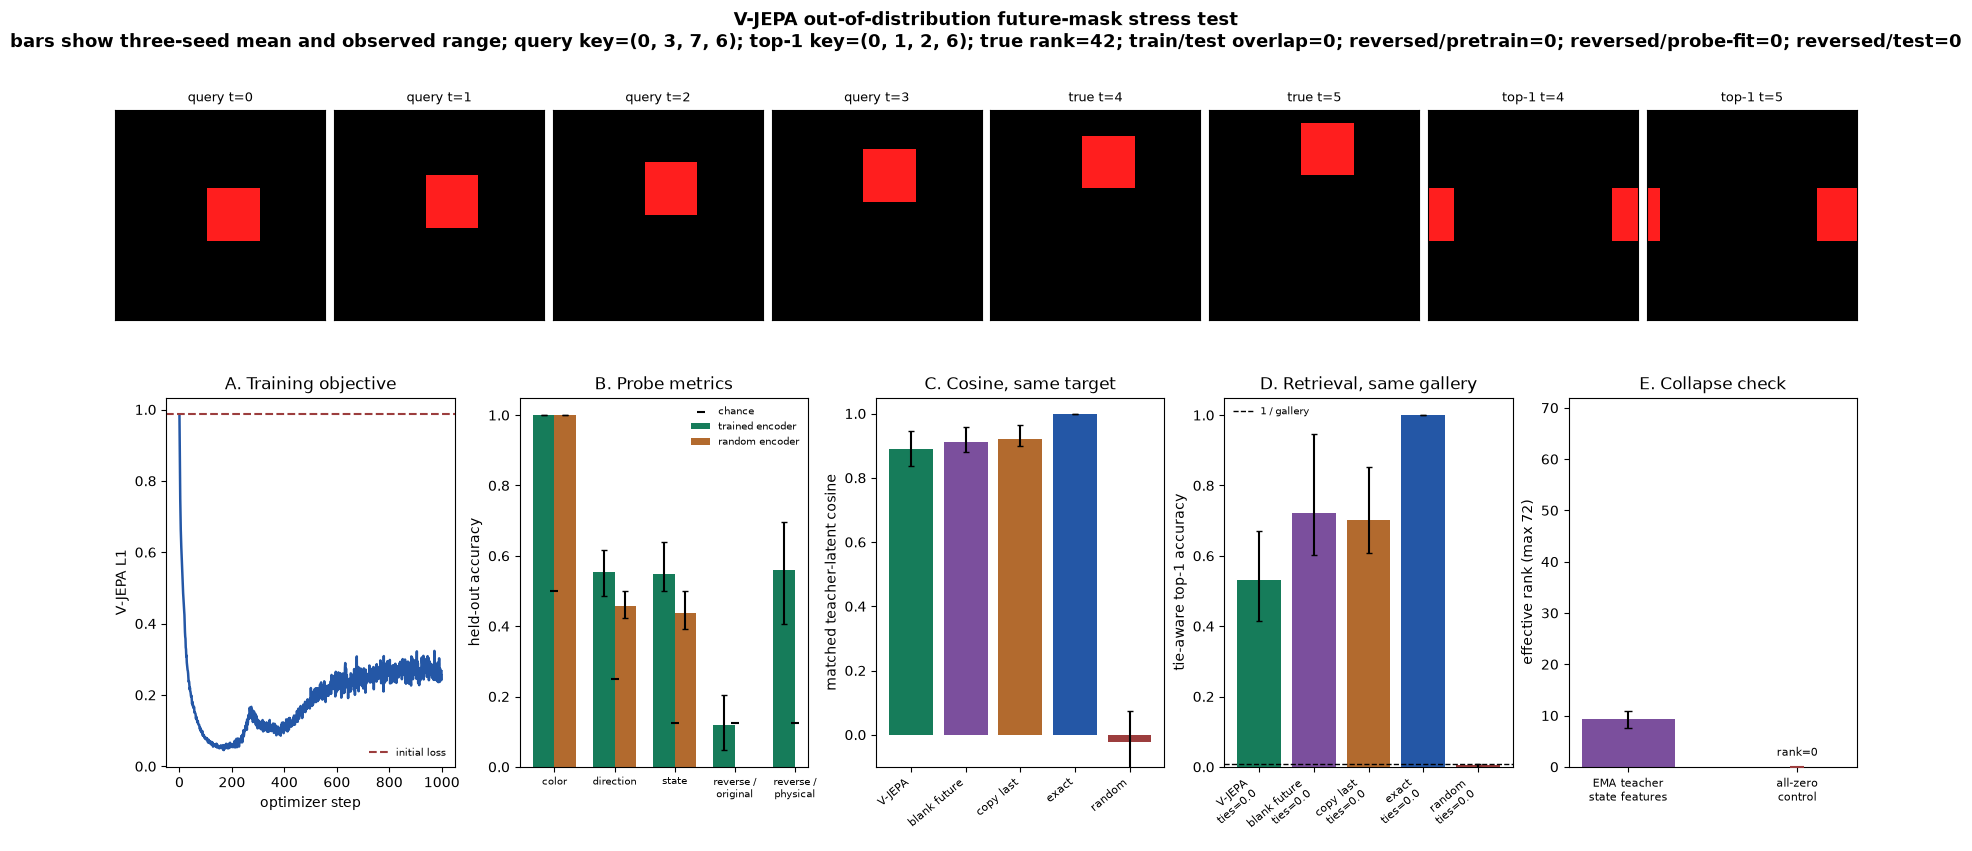

In [19]:
EVAL_SEEDS = (0, 1, 2)
validate_learner_pipeline_dependencies(globals(), reference)

metrics_by_seed = {}
seed_zero_run = None
for seed in EVAL_SEEDS:
    train_world, test_world = make_disjoint_worlds(512, 128, seed=seed, device=device)
    model, history = train_small_vjepa(train_world, steps=1_000, batch_size=64, seed=seed)
    metrics = evaluate_small_vjepa(
        model, train_world, test_world, history, seed=seed, probe_train_examples=128
    )
    metrics_by_seed[seed] = metrics
    if seed == 0:
        seed_zero_run = (model, history, metrics, train_world, test_world)

intervals = summarize_multiseed(metrics_by_seed)
model, history, metrics, train_world, test_world = seed_zero_run

rows = [
    ("final / initial V-JEPA L1", "train_loss_ratio"),
    ("color probe", "color_probe_accuracy"),
    ("direction probe", "direction_probe_accuracy"),
    ("combined-state probe", "state_probe_accuracy"),
    ("random-encoder direction", "random_encoder_direction_accuracy"),
    ("random-encoder state", "random_encoder_state_accuracy"),
    ("reversed / original state", "reversed_original_state_accuracy"),
    ("reversed / physical state", "reversed_physical_state_accuracy"),
    ("future-mask V-JEPA cosine", "predictors.vjepa.teacher_latent_cosine"),
    ("blank-future cosine", "predictors.blank_future.teacher_latent_cosine"),
    ("copy-last-frame cosine", "predictors.copy_last_frame.teacher_latent_cosine"),
    ("exact-dynamics cosine", "predictors.exact_dynamics.teacher_latent_cosine"),
    ("random-predictor cosine", "predictors.random_predictor.teacher_latent_cosine"),
    ("future-mask V-JEPA retrieval", "predictors.vjepa.retrieval_accuracy"),
    ("blank-future retrieval", "predictors.blank_future.retrieval_accuracy"),
    ("copy-last-frame retrieval", "predictors.copy_last_frame.retrieval_accuracy"),
    ("exact-dynamics retrieval", "predictors.exact_dynamics.retrieval_accuracy"),
    ("random-predictor retrieval", "predictors.random_predictor.retrieval_accuracy"),
    ("effective rank / 72", "effective_rank"),
]
table = ["| metric | three-seed mean | observed range |", "|---|---:|---:|"]
for label, name in rows:
    interval = intervals[name]
    table.append(f"| {label} | {interval.mean:.3f} | [{interval.minimum:.3f}, {interval.maximum:.3f}] |")
display(Markdown("\n".join(table)))

tie_table = ["| method | tied queries mean [range] | maximum tie size [range] |", "|---|---:|---:|"]
for label, key in (
    ("future-mask V-JEPA", "vjepa"), ("blank future", "blank_future"),
    ("copy last", "copy_last_frame"), ("exact", "exact_dynamics"), ("random", "random_predictor"),
):
    tied = intervals[f"predictors.{key}.tied_queries"]
    maximum = intervals[f"predictors.{key}.max_tie_count"]
    tie_table.append(
        f"| {label} | {tied.mean:.1f} [{tied.minimum:.0f}, {tied.maximum:.0f}] | "
        f"{maximum.mean:.1f} [{maximum.minimum:.0f}, {maximum.maximum:.0f}] |"
    )
display(Markdown("\n".join(tie_table)))

audit_table = [
    "| seed | train/test overlap | reversed/pretrain | reversed/probe-fit | reversed/test | collision free |",
    "|---:|---:|---:|---:|---:|:---:|",
]
for seed, seed_metrics in metrics_by_seed.items():
    duplicate = seed_metrics.duplicate_audit
    reversal = seed_metrics.reversal_audit
    audit_table.append(
        f"| {seed} | {duplicate.train_test_overlap} | {reversal.reversed_pretraining_overlap} | "
        f"{reversal.reversed_probe_fit_overlap} | {reversal.reversed_test_overlap} | {reversal.collision_free} |"
    )
display(Markdown("\n".join(audit_table)))

for seed_metrics in metrics_by_seed.values():
    assert seed_metrics.duplicate_audit.is_disjoint
    assert seed_metrics.reversal_audit.collision_free
    assert seed_metrics.effective_rank_max == 72
    assert seed_metrics.predictors["exact_dynamics"].teacher_latent_cosine >= 0.999999
    assert seed_metrics.predictors["exact_dynamics"].retrieval_accuracy == 1.0

predicted, target = predict_future_features(model, test_world.videos)
retrieval = retrieval_details(predicted, target, test_world.clip_keys, test_world.clip_keys)
signature_path = assets_dir / "vjepa_from_scratch_signature.png"
fig = make_signature_figure(history, metrics, test_world, retrieval, intervals)
fingerprint_payload = {
    "seed_metrics": asdict(metrics),
    "intervals": {name: asdict(interval) for name, interval in intervals.items()},
}
fig.savefig(
    signature_path,
    dpi=180,
    bbox_inches="tight",
    metadata={
        "EvaluationProtocol": EVALUATION_PROTOCOL_VERSION,
        "EvaluationFingerprint": evaluation_fingerprint(fingerprint_payload),
    },
)
plt.show()


![Expected V-JEPA signature result](../../instructions/assets/vjepa_from_scratch_signature.png)


<details open>
<summary>How to interpret the checked result</summary>

- Across seeds 0, 1, and 2, final/initial L1 is `0.388 [0.343, 0.456]`.
- Future-mask V-JEPA reaches cosine `0.889 [0.838, 0.946]` and retrieval `0.531 [0.414, 0.672]`; persistence reaches cosine `0.922 [0.898, 0.964]` and retrieval `0.703 [0.609, 0.852]`.
- Blank-future reaches cosine `0.913 [0.880, 0.959]` and retrieval `0.721 [0.602, 0.945]` despite having no future pixels. This is the strongest warning against interpreting clip retrieval as future prediction.
- Exact dynamics is `1.000` on both metrics. Random-predictor retrieval is `0.005 [0.000, 0.008]`.
- Effective rank is `9.27 [7.61, 10.97]` out of the attainable 72. Every collision count and tied-query count is zero in all checked seeds.
- The training curve verifies optimization of the paper L1 term under spatial tube masking; it does not by itself verify future extrapolation.
- The future-mask V-JEPA bar is an out-of-distribution stress test. Compare it only with controls scored in the same teacher space.
- Blank-future retrieval measures surviving clip identity without any future pixels. High retrieval on this control exposes context carryover; neither teacher cosine nor clip retrieval isolates predictive dynamics.
- Exact dynamics must reach the teacher target exactly. Persistence is the relevant shortcut, not a straw baseline.
- Tie counts are part of every retrieval claim. Zero split collisions do not imply zero representation ties.
- Reversal metrics are admissible only because the canonical-key audit is collision-free against pretraining and probe-fit keys.
- The observed V-JEPA-minus-persistence differences across three seeds are descriptive, not a confidence interval or an aggregate superiority claim.

The lab's conclusion remains negative. A positive follow-up needs to beat persistence and blank-future
controls in a preregistered setting whose targets distinguish futures for matched contexts; improving these
clip-level metrics alone does not establish dynamics.

</details>


## Try It Yourself

Switch between the in-distribution spatial tube mask and the out-of-distribution future mask, then inspect one query, its target pixels, its retrieved clip, true rank, and tie count.

After inspecting a query, compare its last two real frames with the same clip's blank-future and copy-last-frame controls. None of the teacher-space controls produces a decoded video.


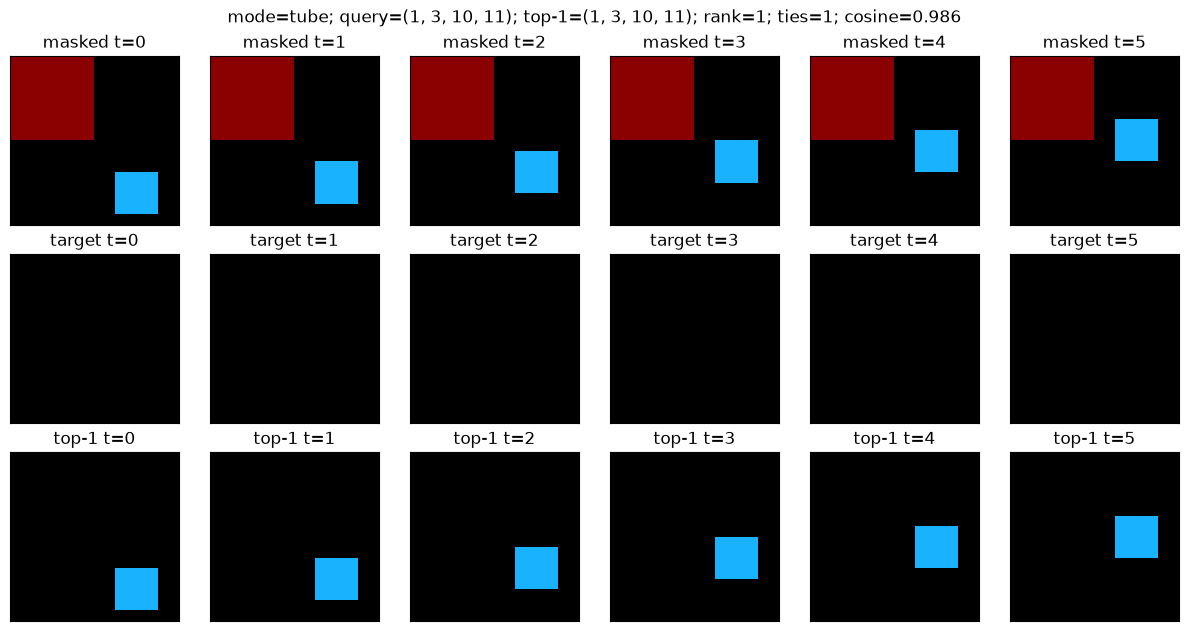

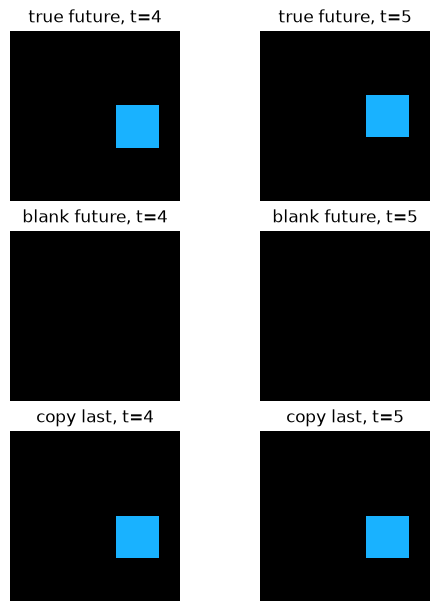

In [20]:
play_mode = "tube"  # "tube" or "future"
play_block = (2, 2)
play_query_index = 7

_, play_grid = model.target_encoder.encode_all(test_world.videos[:1])
if play_mode == "tube":
    one_mask = sample_spatial_tube_mask(
        1,
        play_grid,
        block_shape=play_block,
        generator=t.Generator().manual_seed(17),
        device=device,
    )
elif play_mode == "future":
    one_mask = future_prediction_mask(1, play_grid, device=device)
else:
    raise ValueError("play_mode must be 'tube' or 'future'.")

gallery_mask = one_mask.expand(len(test_world.videos), -1).clone()
with t.no_grad():
    gallery_prediction, gallery_target, _ = model(test_world.videos, gallery_mask)
play_retrieval = retrieval_details(
    gallery_prediction.flatten(1),
    gallery_target.flatten(1),
    test_world.clip_keys,
    test_world.clip_keys,
)
top1_index = int(play_retrieval.top1_indices[play_query_index])
pixel_mask = expand_tubelet_mask(one_mask, play_grid, model.context_encoder.tubelet.tubelet_size)[0]

fig, axes = plt.subplots(3, 6, figsize=(12, 6.2), constrained_layout=True)
for frame_index in range(6):
    axes[0, frame_index].imshow(test_world.videos[play_query_index, frame_index].cpu().permute(1, 2, 0))
    overlay = t.zeros(*pixel_mask[frame_index].shape, 4)
    overlay[..., 0] = 1.0
    overlay[..., 3] = pixel_mask[frame_index].cpu().float() * 0.55
    axes[0, frame_index].imshow(overlay)
    axes[0, frame_index].set_title(f"masked t={frame_index}")

    target_pixels = test_world.videos[play_query_index, frame_index] * pixel_mask[frame_index].to(device)
    axes[1, frame_index].imshow(target_pixels.cpu().permute(1, 2, 0))
    axes[1, frame_index].set_title(f"target t={frame_index}")

    axes[2, frame_index].imshow(test_world.videos[top1_index, frame_index].cpu().permute(1, 2, 0))
    axes[2, frame_index].set_title(f"top-1 t={frame_index}")

for axis in axes.flat:
    axis.set_xticks([])
    axis.set_yticks([])
fig.suptitle(
    f"mode={play_mode}; query={tuple(test_world.clip_keys[play_query_index].tolist())}; "
    f"top-1={tuple(test_world.clip_keys[top1_index].tolist())}; "
    f"rank={int(play_retrieval.true_ranks[play_query_index])}; "
    f"ties={int(play_retrieval.tie_counts[play_query_index])}; "
    f"cosine={float(play_retrieval.matched_cosines[play_query_index]):.3f}"
)
plt.show()

play_controls = {
    "true future": test_world.videos,
    "blank future": blank_future_video(test_world),
    "copy last": copy_last_frame_video(test_world),
}
fig, axes = plt.subplots(3, 2, figsize=(5, 6), constrained_layout=True)
for row, (name, video) in enumerate(play_controls.items()):
    for offset, frame in enumerate((4, 5)):
        axes[row, offset].imshow(video[play_query_index, frame].cpu().permute(1, 2, 0))
        axes[row, offset].set_title(f"{name}, t={frame}")
        axes[row, offset].axis("off")
plt.show()


<details>
<summary>Interpretation guide</summary>

- Strong tube-mask retrieval with weak future-mask retrieval indicates interpolation without demonstrated extrapolation.
- If persistence matches or wins, keep the negative conclusion; do not rescue the claim with probe accuracy.
- If physical reversal does not outperform original-label reversal, inspect static position shortcuts.
- Inspect ties and wraparound failures rather than averaging them away.

</details>

## Further Research / Anomaly Hunting

A positive follow-up needs a preregistered generated process where the visible context contains a predictive
latent state but a frozen final frame does not. Specify the process, metric, persistence margin, seed count,
and stopping rule before training. That is a new experiment, not evidence supplied by this notebook.

## Limitations

- This is a tiny one-object toroidal world with four constant velocities, no occlusion, and no interaction.
- Spatial tube pretraining and full-future evaluation use different mask distributions by design.
- The primary method has no variance or covariance penalty; collapse diagnostics observe the result but do not prevent collapse.
- A random encoder can expose appearance and position, so trained-minus-random probe margins remain descriptive.
- The 96-column readout has an attainable rank bound of 72 because its final 24 columns are algebraically dependent.
- Three seeds provide observed ranges only, not uncertainty estimates.
- Teacher final-slice features attend to the context. Blank-future retrieval tests that shortcut; a matched-context counterfactual-future metric is still needed for a positive dynamics claim.
- This notebook does not reproduce V-JEPA scale, multi-block masking, data augmentation, optimizer schedules, or downstream attentive probes.

## Reading

- [V-JEPA paper](https://arxiv.org/abs/2404.08471)
- [Official V-JEPA repository](https://github.com/facebookresearch/jepa)
- [Released V-JEPA training loop](https://github.com/facebookresearch/jepa/blob/main/app/vjepa/train.py)
- [Released 3D mask generator](https://github.com/facebookresearch/jepa/blob/main/src/masks/multiblock3d.py)
